# 04 - Introducción al aprendizaje no supervisado

**Hecho por:** Joshua Sancho

**Correo:** [joshsan1408@gmail.com](mailto:joshsan1408@gmail.com)

**LinkedIn:** [joshsan1408](https://www.linkedin.com/in/joshsan1408/)

## 1. Comprensión del problema

### 1.1. ¿Qué cambia respecto al aprendizaje supervisado?

En el **aprendizaje supervisado** tenemos una **variable objetivo** o
**target**: la respuesta que queremos aprender a predecir a partir de unas
entradas. Entrenamos con pares de entradas `X` y respuestas conocidas `y`.
En regresión, el target es un valor numérico, como un costo; en clasificación,
es una categoría, como «abandona» o «permanece».

Pero imaginemos que recibimos miles de documentos que nadie ha leído o años
de mediciones de una máquina sin un registro de sus fallas. Hay muchos datos,
pero todavía no sabemos qué categorías usar, o etiquetarlos uno por uno sería
muy costoso. ¿Podemos aprender algo antes de disponer de todas esas respuestas?

El **aprendizaje no supervisado** busca estructura a partir de las entradas,
sin entrenar contra una etiqueta objetivo externa para cada ejemplo. Puede
reunir observaciones similares, representar los datos de una forma más útil o
señalar comportamientos poco habituales.

**Ejemplo:** tenemos edad, frecuencia de compra e importe de miles de clientes,
pero ninguna columna que diga qué tipo de cliente es cada uno. Podemos explorar
si aparecen perfiles distintos antes de inventar una lista de categorías.
En cambio, si ya tuviéramos etiquetas como «abandona» y «permanece», predecirlas
sería un problema de clasificación supervisada: esas etiquetas serían el target.

«Sin supervisión» no significa «sin decisiones humanas». Elegimos qué medir,
qué transformaciones aplicar, cómo comparar ejemplos y qué resultados resultan
útiles. Esas decisiones influyen en la estructura que encontraremos.


### 1.2. ¿Por qué tiene tanto valor cuando hay muchos datos y pocas etiquetas?

**Un dato y una etiqueta no son lo mismo.** Registrar una fotografía, una
lectura de temperatura o un registro de actividad puede ser automático.
Saber si la foto contiene un defecto, si el registro corresponde a un problema
o si la máquina va a fallar puede requerir revisión especializada y tiempo
de seguimiento.

Podemos tener un millón de observaciones y solo unos cientos revisados.
Además, a veces ni siquiera conocemos todas las categorías que valdría la pena
buscar. El aprendizaje no supervisado ayuda a aprovechar esas observaciones
para formular preguntas, organizar la revisión y construir representaciones.

| Situación | Qué podemos hacer | Para qué nos sirve |
| --- | --- | --- |
| Muchos documentos sin categorías. | Agruparlos por similitud de contenido. | Explorar temas y proponer una primera taxonomía. |
| Miles de clientes con hábitos distintos. | Descubrir perfiles de comportamiento. | Describir necesidades y plantear acciones para estudiar después. |
| Sensores con pocas fallas registradas. | Modelar funcionamiento habitual y buscar desviaciones. | Priorizar inspecciones. |
| Imágenes o textos con pocas etiquetas. | Aprender una representación antes de clasificar. | Aprovechar información de ejemplos sin anotación. |
| Mediciones repetidas o muy relacionadas. | Reducir dimensiones. | Visualizar, comprimir y estudiar variaciones principales. |
| Compras o eventos registrados juntos. | Descubrir reglas de asociación. | Identificar combinaciones frecuentes y explorar recomendaciones. |

No estamos obligados a elegir una sola familia de aprendizaje para todo el
proyecto. Podemos empezar explorando sin etiquetas, pedir revisión humana de
algunos ejemplos y terminar construyendo un clasificador supervisado.


### 1.3. Aplicaciones del aprendizaje no supervisado: grupos, representación, anomalías y asociaciones

El aprendizaje no supervisado tiene distintas aplicaciones. Cuatro de las más
habituales son el **agrupamiento**, la **reducción de dimensiones**, la
**detección de anomalías** y las **reglas de asociación**. Todas permiten aprovechar datos sin una variable
objetivo (`target`) etiquetada para cada ejemplo, pero responden preguntas
diferentes:


**Agrupamiento o clustering:** «¿qué observaciones se parecen entre sí?».
Produce identificadores de grupo, como `0`, `1` y `2`. En este laboratorio,
agruparemos colores parecidos y usaremos un color representativo de cada grupo.

**Reducción de dimensiones:** «¿podemos describir estas observaciones con menos
coordenadas conservando información útil?». PCA busca direcciones que resumen
variación lineal; t-SNE permite explorar vecindades en un gráfico. Ninguno
necesita que le entreguemos una clase para cada fila. La proyección y el
agrupamiento son operaciones distintas: un dibujo de dos ejes no sustituye
una validación de los grupos.

**Detección de anomalías:** «¿qué observaciones se apartan de lo habitual?».
Produce un puntaje de rareza o una señal de revisión. Nos interesa cuando
los eventos relevantes son escasos o pueden adoptar formas que no hemos visto.

**Reglas de asociación:** «¿qué elementos tienden a aparecer juntos?».
Descubren relaciones frecuentes entre productos, acciones o atributos, sin
necesitar una variable objetivo. Pueden servir para explorar hábitos de compra,
orientar recomendaciones o estudiar eventos que coocurren. A diferencia del
clustering, buscan relaciones entre elementos en lugar de repartir las
observaciones en grupos. Una asociación no demuestra causalidad.

En estas aplicaciones necesitamos una **representación**: los valores con los que
describimos cada ejemplo. Cambiar las entradas cambia lo que significa
«parecido». Agrupar clientes por gasto puede revelar perfiles distintos a
agruparlos por horarios de visita, aunque sean las mismas personas.

Fuentes: [scikit-learn: clustering](https://scikit-learn.org/stable/modules/clustering.html),
[reducción de dimensiones](https://scikit-learn.org/stable/modules/decomposition.html)
[detección de anomalías](https://scikit-learn.org/stable/modules/outlier_detection.html)
y [reglas de asociación](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/).


### 1.4. Descubrir grupos que todavía no sabíamos nombrar

Para entrenar un clasificador necesitamos definir qué queremos clasificar.
Si nadie ha identificado todavía los perfiles relevantes, no podemos darle
etiquetas fiables al modelo. El clustering puede ayudarnos a **descubrir una
organización inicial** de los datos antes de definir esas categorías.

**Ejemplo hipotético:** una plataforma educativa registra visitas semanales,
duración de sesiones, recursos consultados y entregas. No tiene etiquetas
sobre estrategias de estudio. Después de preparar las entradas y agruparlas,
podrían aparecer estos perfiles:

| Grupo descubierto | Qué observamos al describirlo | Hipótesis para investigar |
| --- | --- | --- |
| A | Visitas frecuentes y sesiones cortas. | Estudio distribuido a lo largo de la semana. |
| B | Pocas visitas y sesiones largas antes de una entrega. | Concentración del trabajo cerca de las fechas límite. |
| C | Muchos recursos abiertos y pocas entregas. | Exploración o posibles dificultades para completar tareas. |

Los nombres y explicaciones los proponemos **después de revisar los datos**.
El algoritmo no sabe qué es una dificultad de aprendizaje. El grupo C también
podría incluir estudiantes que descargan materiales y trabajan fuera de la
plataforma. Necesitamos contrastar esa hipótesis con otras observaciones.

Un recorrido razonable sería preparar las entradas, formar grupos, comparar
sus tamaños y distribuciones, revisar ejemplos representativos y casos de
frontera, y conversar con personas que conozcan el contexto. Después podemos
repetir el análisis con otras muestras para ver qué patrones se mantienen.

Esto nos permite empezar a estudiar grupos que no habíamos previsto. No
significa que los grupos sean categorías naturales, permanentes o causales.
Si las observaciones **cambian gradualmente y no hay separaciones claras**,
el algoritmo puede dividirlas en grupos de todos modos. Pensemos en colores
que pasan poco a poco del azul al verde: hay tonos intermedios y no un corte
evidente que indique dónde termina un grupo y empieza otro.

También puede ocurrir que **una variable influya mucho más que las demás en la
separación**, aunque no sea la que nos interesa estudiar. Por ejemplo, queremos
explorar hábitos de compra usando gasto mensual y frecuencia de visitas, pero
los grupos terminan diferenciándose principalmente por el gasto. Si no escalamos
las entradas y el gasto tiene valores mucho mayores que el número de visitas,
puede pesar más al calcular distancias. Escalar ayuda con esa diferencia de
magnitud, pero también necesitamos elegir entradas relevantes y revisar qué
variables distinguen realmente a los grupos.

**Preguntas para interpretar:** ¿qué entradas distinguen a los grupos?, ¿hay
subgrupos o casos mezclados?, ¿cambia la conclusión al escalar las variables?,
¿el patrón se mantiene en otro periodo?, ¿la diferencia permite una acción útil?


### 1.5. ¿Qué ocurre con una clasificación extremadamente desbalanceada?

Un conjunto está **desbalanceado** cuando unas clases tienen muchos más ejemplos
que otras. Un caso extremo aparece cuando queremos detectar eventos de una
clase muy poco frecuente, como defectos excepcionales o fallas de una máquina.
La pregunta ya no es solo cuántos ejemplos acertamos, sino si encontramos esos
pocos casos relevantes sin generar un volumen inmanejable de falsas alarmas.

**Ejemplo ficticio:** tenemos 100.000 observaciones: 100 pertenecen a la
**clase de interés**, que queremos detectar, y 99.900 a la clase habitual.
Un sistema que siempre responde «clase habitual» obtiene:

- **Accuracy:** `99.900 / 100.000 = 99,9 %`.
- **Recall de la clase de interés:** `0 / 100 = 0 %`.

La accuracy parece excelente, pero el sistema no detecta ningún caso de la
clase de interés. Además, entrenar con solo 100 casos de esa clase limita la
variedad de ejemplos que podemos mostrarle a un clasificador.

Un enfoque posible cambia la pregunta: en lugar de aprender todas las formas
que puede adoptar la clase poco frecuente, intentamos aprender **cómo suelen
ser las observaciones habituales** y señalamos las que se alejan de ese patrón.
Así podemos explorar la detección de anomalías, sin necesitar muchos ejemplos
etiquetados de cada tipo de evento poco frecuente.

Esto resulta especialmente interesante si los eventos son raros, sus etiquetas
llegan tarde o los comportamientos cambian. Pero **desbalance no equivale a
anomalía**: un caso de la clase habitual puede tener características inusuales,
y uno de la clase de interés puede parecerse mucho a los casos habituales.
La utilidad del enfoque depende de que la rareza ayude a distinguir los casos
que queremos detectar; pertenecer a una clase minoritaria no basta para ser
una anomalía.

Si tenemos etiquetas suficientes, también podemos estudiar pesos de clase,
muestreo dentro de entrenamiento y cambios de umbral en un clasificador.
La detección de anomalías es una alternativa o un complemento; el desbalance
por sí solo no demuestra que sea la mejor solución.


### 1.6. Detección de anomalías: aprender lo habitual para priorizar lo raro

Hay dos escenarios que conviene distinguir:

| Escenario | Qué datos usamos al ajustar | Qué buscamos |
| --- | --- | --- |
| Detección de valores atípicos (*outlier detection*). | Un conjunto mezclado que puede contener casos extraños. | Identificar observaciones que se apartan de las concentraciones habituales. |
| Detección de novedades (*novelty detection*). | Datos considerados normales. | Detectar futuras observaciones que no encajan con ese funcionamiento. |

El segundo escenario también se llama detección de anomalías **semi supervisada**
en parte de la literatura: conocemos qué ejemplos representan normalidad,
aunque no tengamos ejemplos de todos los tipos de anomalía. Es un uso distinto
del término frente a la clasificación semi supervisada que veremos después.

Fuente: [scikit-learn: outliers y novedades](https://scikit-learn.org/stable/modules/outlier_detection.html).

#### Algunas maneras de asignar rareza

- **Isolation Forest:** hace particiones aleatorias de las entradas. Los casos
  que se aíslan con pocos cortes tienden a recibir mayor rareza. Su puntaje indica qué tan inusual es una
  observación, no la probabilidad de que pertenezca a una clase concreta.
- **Local Outlier Factor (LOF):** compara la densidad alrededor de una observación
  con la de sus vecinos. Puede detectar un caso aislado respecto a su entorno,
  aunque existan otras regiones de comportamiento habitual con una densidad diferente.
- **Distancia a grupos:** un punto muy alejado de los centros puede merecer revisión.
  Funciona mejor si esos centros describen adecuadamente lo habitual. Un pequeño
  grupo normal no debería confundirse automáticamente con una anomalía.

Fuentes: [IsolationForest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)
y [LocalOutlierFactor](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html).

<img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_anomaly_comparison_001.png" alt="Comparación de detectores de anomalías sobre conjuntos sintéticos con distribuciones y densidades diferentes." width="950" style="background-color: white;">

**Cómo leer la imagen:** cada columna corresponde a un detector y cada fila
a un conjunto de puntos distinto. Los puntos naranjas representan casos habituales
y los azules, anomalías conocidas en este ejemplo artificial. Las líneas
negras muestran fronteras de decisión; LOF presenta puntajes locales en lugar
de dibujar esa misma frontera. Si comparamos los resultados de una misma fila,
vemos que los detectores delimitan de manera diferente las regiones habituales.
Podemos centrarnos en cómo influyen la forma y la densidad de los datos,
sin memorizar todos los nombres.
Fuente: [scikit-learn: comparación de detectores](https://scikit-learn.org/stable/auto_examples/miscellaneous/plot_anomaly_comparison.html).


### 1.7. Del puntaje de anomalía a la decisión de revisar un caso

El detector calcula qué tan inusual parece cada observación. Después necesitamos
una regla para decidir **cuáles vamos a revisar**. Podemos señalar los casos que
superen un **umbral**, es decir, un valor de corte, o seleccionar los casos más
inusuales hasta completar nuestra capacidad de revisión.

Si hacemos la regla más exigente, tendremos menos alertas, pero podemos dejar
fuera casos importantes. Si la hacemos menos exigente, revisaremos más casos,
incluyendo más observaciones que solo parecían extrañas.

#### ¿Por qué muchas alertas pueden resultar poco útiles?

Retomemos el ejemplo: de 100.000 observaciones, solo 100 pertenecen a la clase
que nos interesa detectar. Las otras 99.900 pertenecen a la clase habitual.
Supongamos que revisamos las alertas y encontramos lo siguiente:

| Resultado | Cantidad |
| --- | ---: |
| Casos de interés que detectamos. | 80 de los 100 existentes. |
| Casos habituales que señalamos por error. | 999 de los 99.900 existentes. |
| Total de alertas que debemos revisar. | `80 + 999 = 1079`. |

**Encontramos el 80 % de los casos de interés**, pero solo **80 de las 1079
alertas son casos de interés: un 7,41 %**. Las otras 999 son falsas alarmas.
Aunque solo señalamos por error al 1 % de la clase habitual, esa clase es tan
grande que produce muchas más alertas que los casos que queríamos encontrar.

Son dos preguntas distintas:

- **Recall:** de todos los casos de interés que existían, ¿cuántos encontramos?
  Aquí encontramos `80 / 100 = 80 %`.
- **Precisión:** de todos los casos que señalamos, ¿cuántos eran de interés?
  Aquí acertamos en `80 / 1079 = 7,41 %` de las alertas.

Para decidir si el sistema nos sirve, necesitamos mirar ambas y considerar
cuántos casos podemos revisar. Un detector que encuentra muchos casos de interés
puede exigir demasiado trabajo si también genera muchas falsas alarmas.

#### ¿Cómo comprobamos si la regla funciona?

Para calcular estos resultados necesitamos **etiquetas revisadas** que indiquen
qué casos eran realmente de interés. El puntaje de rareza, por sí solo, no nos
da esa respuesta.

Podemos ajustar el modelo con un conjunto de datos y probar distintos cortes
en otro conjunto revisado, llamado **validación**. Una vez elegido el corte,
lo evaluamos en un conjunto adicional que mantuvimos reservado, llamado
**prueba**. Así comprobamos el resultado sin cambiar la regla para favorecer
los mismos ejemplos con los que la estamos evaluando.

También necesitamos revisar una muestra de los casos **no señalados**. Si solo
revisamos las alertas, podemos conocer cuáles eran falsas alarmas, pero no
cuántos casos importantes dejamos escapar.

#### ¿Qué significa `contamination`?

En algunos detectores, este parámetro permite indicar una **proporción supuesta
de anomalías** para establecer el corte. Por ejemplo, `contamination=0.01`
orienta el corte para señalar aproximadamente el 1 % de los datos usados para
ajustarlo, según el detector y los posibles empates en los puntajes.

**No significa que hayamos demostrado que el 1 % de los datos contiene un
problema.** Estamos dando al modelo una referencia para decidir dónde cortar;
los casos señalados todavía necesitan comprobarse. Esa proporción tampoco
garantiza que se señale el mismo porcentaje en datos nuevos.

Por último, lo habitual puede cambiar con el tiempo. Un patrón nuevo y esperado
puede resultar extraño para un modelo ajustado con datos antiguos. Por eso
revisamos periódicamente las alertas y comprobamos si siguen siendo útiles.

Fuentes: [scikit-learn: precisión y recall al variar el umbral](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html)
y [IsolationForest: parámetro contamination](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html).


### 1.8. Conectar clustering y revisión humana para construir etiquetas

Descubrir grupos también puede ayudarnos a **organizar el trabajo de anotación**.
En lugar de revisar ejemplos sin ningún orden, podemos seleccionar observaciones
de distintos grupos, incluyendo centros, fronteras y puntos poco habituales.
Así buscamos cubrir comportamientos diversos con el tiempo de revisión disponible.

**Ejemplo hipotético:** tenemos 10.000 comentarios de soporte sin categorías.
Los representamos numéricamente y encontramos grupos de comentarios similares.
Una persona revisa varios ejemplos de cada grupo y descubre temas como acceso,
pagos y errores técnicos. Con esa exploración propone categorías y etiqueta
un primer conjunto de comentarios.

El identificador del grupo todavía no es una etiqueta semántica. Un mismo grupo
puede mezclar dos temas y un mismo tema puede aparecer en varios grupos.
Por eso no deberíamos revisar una sola observación y copiar su etiqueta a todo
el grupo como si todas las respuestas hubieran sido confirmadas.

Conviene mantener el origen de cada etiqueta:

| Tipo | Qué es y de dónde sale | Cómo la tratamos |
| --- | --- | --- |
| Etiqueta revisada. | Etiqueta otorgada por una persona o un proceso fiable tras revisar el caso. Por ejemplo, «problema de acceso». | La usamos como referencia, aunque puede contener errores de anotación. |
| Identificador de cluster. | Número o nombre que asigna un algoritmo para indicar a qué grupo pertenece una observación. Por ejemplo, «grupo 3»; no indica por sí solo qué significa ese grupo. | Lo usamos para explorar observaciones similares, sin asumir que todas pertenecen a una misma clase conocida. |
| Pseudoetiqueta. | Etiqueta asignada automáticamente a un caso sin revisar, que usamos como respuesta provisional para entrenar un modelo. Por ejemplo, «problema de acceso», inferido por un clasificador. | La tratamos como una respuesta que puede ser incorrecta y la distinguimos de las etiquetas revisadas. |

Podemos usar estas primeras etiquetas para entrenar un clasificador. Después,
el modelo puede ayudarnos a seleccionar qué comentarios conviene pedirle a una
persona que revise, por ejemplo, aquellos en los que tiene más dudas. A esto
lo llamamos **aprendizaje activo**: elegir qué casos enviar a revisión humana
para aprovechar mejor el tiempo disponible y usar las nuevas etiquetas para
seguir entrenando.

Si además aprovechamos los casos sin etiquetar durante el entrenamiento,
hablamos de **aprendizaje semi supervisado**, que explicamos a continuación.
Ambas estrategias se pueden combinar.

Fuente para un ejemplo de selección de consultas: [scikit-learn: propagación de etiquetas y aprendizaje activo](https://scikit-learn.org/stable/auto_examples/semi_supervised/plot_label_propagation_digits_active_learning.html).


### 1.9. Aprendizaje semi supervisado: pocas etiquetas y muchos ejemplos

En clasificación **semi supervisada** tenemos una parte de los datos con
etiquetas y otra sin ellas. Intentamos que ambas aporten información al ajuste.
La idea necesita un supuesto: la estructura o similitud de las entradas debe
estar relacionada con las clases que queremos predecir.

Si documentos cercanos por contenido suelen compartir tema, esa cercanía puede
ayudar. Si se agrupan por longitud mientras queremos clasificar intención,
propagar etiquetas por esos grupos puede perjudicar el resultado.
Fuente: [scikit-learn: aprendizaje semi supervisado](https://scikit-learn.org/stable/modules/semi_supervised.html).

#### Propagación de etiquetas: compartir información entre vecinos

Construimos un grafo de similitudes, es decir, un conjunto de ejemplos
conectados según su cercanía. Los ejemplos son nodos y sus conexiones
representan cercanía. Algunas etiquetas conocidas actúan como puntos de partida;
el procedimiento transmite información por las conexiones hacia los ejemplos
sin etiqueta. `LabelPropagation` y `LabelSpreading` implementan variantes de
esta idea; no exigen formar primero clusters con K-Means.

<img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_label_propagation_structure_001.png" alt="Dos anillos con dos etiquetas iniciales y el resto de puntos sin etiquetar." width="400" style="background-color: white;">
<img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_label_propagation_structure_002.png" alt="Resultado de Label Spreading: etiquetas inferidas siguiendo los dos anillos." width="400" style="background-color: white;">

**Cómo leer la imagen:** a la izquierda hay dos anillos con muy pocos puntos
etiquetados; a la derecha, etiquetas inferidas siguiendo la estructura de los
vecinos. El ejemplo muestra por qué la conectividad puede ayudar cuando una
frontera lineal sería inadecuada. Es una demostración controlada: en datos reales
puede haber conexiones entre clases y etiquetas iniciales erróneas.
Fuente: [scikit-learn: propagación en anillos](https://scikit-learn.org/stable/auto_examples/semi_supervised/plot_label_propagation_structure.html).

Contar con pocas observaciones etiquetadas puede funcionar si cubren las clases
y sus variaciones relevantes. No hay garantía de que una etiqueta por grupo
baste. Si una categoría no está representada en las etiquetas iniciales, el
clasificador no aprenderá automáticamente a reconocerla como una categoría nueva.

Fuente: [LabelSpreading](https://scikit-learn.org/stable/modules/generated/sklearn.semi_supervised.LabelSpreading.html).


### 1.10. Autoentrenamiento y pseudoetiquetas: ampliar con cuidado

Otra estrategia comienza con un clasificador entrenado sobre las etiquetas
revisadas. Ese clasificador predice casos sin etiqueta y añade al entrenamiento
algunas predicciones seleccionadas como **pseudoetiquetas**. Después se reajusta
y puede repetir el proceso. A esto se le llama **autoentrenamiento** o
*self-training*.

Por ejemplo, podríamos partir de 200 comentarios revisados, predecir los demás
y seleccionar solo algunos casos con alta confianza estimada. Debemos conservar
cuáles fueron revisados y cuáles fueron inferidos. La confianza puede estar
mal calibrada: un modelo también puede equivocarse con mucha seguridad.

El principal riesgo es un ciclo de confirmación: el modelo se equivoca,
convierte el error en una pseudoetiqueta y vuelve a entrenar como si esa respuesta
fuera cierta. En desbalance, además, puede añadir casi solo ejemplos de la
clase mayoritaria y reforzar la falta de cobertura de la minoritaria.
Fuente: [SelfTrainingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.semi_supervised.SelfTrainingClassifier.html).

Podemos exigir consistencia entre versiones de un ejemplo. **FixMatch**, por
ejemplo, combina pseudoetiquetas de alta confianza con transformaciones suaves
y fuertes de imágenes. La predicción sobre una versión guía el aprendizaje de
otra. Las transformaciones deben conservar la clase: girar o recortar sin
criterio puede cambiar lo que queremos reconocer.
Fuente: [Sohn y colaboradores: FixMatch](https://arxiv.org/abs/2001.07685).

Para saber si el esfuerzo ayuda, comparamos con un clasificador entrenado solo
con etiquetas revisadas. Reservamos validación y prueba con etiquetas de
referencia, y nunca rellenamos esas respuestas con pseudoetiquetas para luego
contarlas como aciertos. En una evaluación de casos nuevos, mantenemos la prueba
fuera de la construcción de grupos, representaciones y reglas de selección.


### 1.11. Aprendizaje autosupervisado: crear una tarea desde los propios datos

**Autosupervisado** (*self-supervised*) no significa lo mismo que autoentrenamiento.
En el aprendizaje autosupervisado construimos una señal de entrenamiento a
partir del propio dato. No necesitamos una persona que etiquete esa tarea para
cada ejemplo. El objetivo inicial suele ser aprender una **representación**
útil, que después podamos aprovechar en otra tarea.

**Ejemplo con texto:** ocultamos una palabra de una frase y pedimos al modelo
que la prediga usando el contexto. La palabra original proporciona la respuesta.
Para hacerlo bien, el modelo necesita aprender regularidades del lenguaje.
BERT utiliza predicción de elementos enmascarados como parte de su preentrenamiento.
La palabra oculta no es una etiqueta externa como «comentario urgente».
Fuente: [Devlin y colaboradores: BERT](https://arxiv.org/abs/1810.04805).

<img src="https://jalammar.github.io/images/BERT-language-modeling-masked-lm.png" alt="BERT recibe una frase con una palabra oculta mediante MASK y calcula posibles palabras para recuperar la original." width="850" style="background-color: white;">

**Cómo leer la imagen:** empezamos abajo, con la frase original. La palabra
«improvisation» se sustituye por `[MASK]`, que indica una posición oculta.
El modelo recibe la frase con ese hueco y utiliza el contexto para predecir
la palabra que falta. Arriba aparecen posibles palabras y sus probabilidades.
Durante el entrenamiento conocemos la palabra original, así que podemos
compararla con la predicción sin pedir a una persona que etiquete la frase.
El bloque superior convierte la salida del modelo en probabilidades sobre el
vocabulario; los valores mostrados son ilustrativos.
Fuente: [Jay Alammar: The Illustrated BERT](https://jalammar.github.io/illustrated-bert/),
[CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/).


**Ejemplo con imágenes:** creamos dos versiones de la misma fotografía mediante
transformaciones que conserven su contenido relevante y aprendemos a relacionar
sus representaciones. En aprendizaje contrastivo, métodos como **SimCLR**
usan esa relación junto con comparaciones con otras imágenes para aprender
características. No necesitamos indicar «esto es un gato» durante ese paso.
Fuente: [Chen y colaboradores: SimCLR](https://arxiv.org/abs/2002.05709).

<img src="https://simclr.github.io/SimCLR.png" alt="SimCLR obtiene dos versiones de una foto de un perro y dos de una silla; acerca las representaciones de la misma imagen y separa las de imágenes distintas." width="700" style="background-color: white;">

**Cómo leer la imagen:** empezamos abajo. De cada fotografía obtenemos dos
versiones mediante recortes o cambios de color. Los bloques de la red neuronal las
convierten en vectores de números, representados por las pequeñas barras.
Las flechas verdes, **Attract**, indican que acercamos los vectores de las dos
versiones de una misma imagen; las rojas, **Repel**, que separamos los de
imágenes distintas durante esta tarea de entrenamiento. Esa cercanía ocurre
en el espacio de los vectores, no moviendo las fotografías.
La señal para aprender procede de saber qué versiones salieron de la misma
foto; no necesitamos proporcionar las etiquetas «perro» y «silla».
Fuente: [Chen y colaboradores: página oficial de SimCLR](https://simclr.github.io/).


Una representación aprendida, también llamada **embedding**, es un vector de
números que describe un ejemplo. En lugar de diseñar a mano todas las entradas,
podemos aprenderlas con muchos datos sin etiquetas de la tarea final. Después
usamos un conjunto menor etiquetado para entrenar una cabeza de clasificación
o ajustar el modelo completo.

Eso puede reducir la necesidad de anotaciones, pero no garantiza que unas pocas
sean suficientes: depende del preentrenamiento, del cambio de dominio y de la
cobertura de clases. La evaluación de la clasificación final sigue necesitando
etiquetas fiables que no hayan servido para seleccionar la solución.


### 1.12. Entrenar una red neuronal sin etiquetas humanas usando clustering

Una **red neuronal** puede convertir cada imagen en un vector de números que describe sus
características: su **representación**. La forma en que produce esos números
cambia cuando entrenamos la red neuronal. Nos interesa que esa representación permita
comparar imágenes y reconocer diferencias útiles.

**DeepCluster** combina esa red neuronal con un algoritmo de agrupamiento. Agrupamos
las imágenes usando las representaciones que produce la red neuronal y obtenemos
identificadores como «grupo 1», «grupo 2» y «grupo 3». Después usamos esos
identificadores como **pseudoetiquetas**: entrenamos la red neuronal para predecir a qué
grupo fue asignada cada imagen.

Por ejemplo, si una imagen quedó en el grupo 2, usamos «grupo 2» como respuesta
provisional durante ese entrenamiento. No necesitamos saber si muestra un gato
o un automóvil. La respuesta procede del agrupamiento, no de una persona que
haya identificado el contenido de la imagen.

Al entrenar para distinguir esos grupos, ajustamos la red neuronal y, con ello, la forma
en que representa las imágenes. Entonces calculamos nuevas representaciones y
**volvemos a agrupar**. Los grupos pueden cambiar, por lo que actualizamos las
pseudoetiquetas y repetimos el proceso.

La idea central es que **el agrupamiento proporciona respuestas provisionales
para entrenar la red neuronal, y la red neuronal proporciona las representaciones para volver a
agrupar**. Buscamos aprender características útiles sin necesitar categorías
humanas para todas las imágenes. No suponemos que cada grupo sea una clase real
ni que las primeras asignaciones sean correctas.

Después podemos aprovechar la representación aprendida para otra tarea, como
clasificar imágenes con un conjunto etiquetado más pequeño. Para comprobar si
sirve, evaluamos esa tarea con etiquetas revisadas y datos reservados; formar
grupos por sí solo no demuestra que la representación haya mejorado.

Fuente: [Caron y colaboradores: Deep Clustering](https://arxiv.org/abs/1807.05520).


### 1.13. Un mapa para no confundir los conceptos

| Enfoque | Señal disponible durante el aprendizaje | Qué obtenemos o buscamos |
| --- | --- | --- |
| Supervisado. | Etiquetas externas para los ejemplos usados en el ajuste supervisado. | Predecir una respuesta definida. |
| No supervisado. | Entradas sin una etiqueta objetivo externa por ejemplo. | Estructura, grupos, representaciones, rareza o asociaciones. |
| Semi supervisado. | Una parte etiquetada y otra sin etiquetar. | Mejorar una tarea definida aprovechando ambas. |
| Autosupervisado. | Una tarea cuya señal se construye desde los datos. | Aprender representaciones que puedan transferirse. |
| Autoentrenamiento. | Etiquetas iniciales y predicciones seleccionadas como pseudoetiquetas. | Ampliar el entrenamiento dentro de un enfoque semi supervisado. |
| Aprendizaje activo. | Un proceso para consultar etiquetas de ejemplos elegidos. | Usar mejor el presupuesto de revisión. |

Las fronteras de vocabulario varían entre publicaciones: a menudo se incluye
la autosupervisión dentro del aprendizaje sin etiquetas humanas. Aquí
explicitamos de dónde sale la señal para entender qué está aprendiendo el
modelo y qué información sigue aportando una persona.

Antes de elegir un enfoque, conviene formular cuatro preguntas:

1. **¿Ya conocemos las clases que queremos predecir?** Si no, explorar grupos
   puede ayudarnos a definirlas y a descubrir casos que no habíamos considerado.
2. **¿Tenemos ejemplos de los eventos raros o principalmente de normalidad?**
   Esto orienta la comparación entre clasificación y detección de anomalías.
3. **¿La similitud de las entradas está relacionada con nuestro objetivo?**
   Si no lo está, agrupar o propagar etiquetas puede reforzar un patrón irrelevante.
4. **¿Cómo comprobaremos que funciona?** Necesitamos evidencia independiente,
   revisión de errores y métricas que respondan al problema real.

Aprender sin etiquetas no elimina la evaluación. Cambia qué evidencia usamos
en cada etapa y hace especialmente importante interpretar lo que descubrimos.


### 1.14. Nuestro laboratorio: descubrir la estructura de color de una obra

Aquí una fila representa un **píxel de una imagen reducida**. Sus entradas
describen el color en CIELAB y no tenemos una columna con su «color correcto»
ni una paleta objetivo etiquetada. Usaremos **K-Means, HDBSCAN y Mean Shift**
para reunir colores parecidos y construir una paleta representativa.

Imaginemos una pintura con cielo azul, árboles verdes y un camino marrón.
Los grupos pueden resumir esas familias de tonos, pero el modelo no aprende
los nombres «cielo», «árbol» o «camino». Los identificadores `0`, `1` y `2`
son arbitrarios y pueden cambiar entre ajustes.

Este caso permite practicar cómo elegir una representación, comparar reglas
de similitud, buscar hiperparámetros y leer métricas sin una respuesta externa.

Al final, las preguntas son concretas: ¿qué colores conserva cada algoritmo?,
¿cuáles deja fuera?, ¿qué efecto tiene pedir más grupos o cambiar la escala?,
¿el resultado sirve para el uso visual que tenemos en mente?


In [1]:
import math
from abc import ABC, abstractmethod
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from hdbscan import HDBSCAN
from matplotlib.axes import Axes
from PIL import Image
from skimage import color
from sklearn.base import BaseEstimator
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.utils import resample

## 2. Comprensión de los datos

### Cargar y revisar las imágenes

Trabajamos con los archivos de la carpeta `images`, relativa al directorio
actual del notebook. Para usar la ruta por defecto, ejecutamos desde
`notebooks/day-04`, donde debe estar esa carpeta con las pinturas.
`ImageLoader` reconoce archivos `.jpg`, `.jpeg` y `.png`.

El conjunto incluye abstracciones, composiciones monocromáticas y escenas con
muchos detalles. Nos interesa observar si los modelos resumen grandes masas
de color o conservan matices pequeños. Son ejemplos de exploración; no bastan
para demostrar que un algoritmo será mejor en cualquier obra.

`load_image()` devuelve la ruta de una imagen y avisa si no existe.
`plot_images()` permite revisar una galería; aquí definimos la clase y más
adelante cargamos cada obra desde `Main`.

La carpeta `images/` contiene las diez pinturas con los nombres utilizados en
las llamadas a `app.run_analysis()`.


### La clase `ImageLoader`: encontrar y abrir las pinturas

Esta clase reúne las tareas de acceso a las imágenes. Al crear un objeto
`ImageLoader`, indicamos la carpeta donde están las pinturas y se obtiene la
lista de archivos disponibles. Después podemos pedir la ruta de una pintura
por su nombre o mostrar una galería para revisar los archivos.

Nos permite separar la búsqueda de imágenes del procesamiento de sus colores.
Todavía no transforma píxeles ni entrena modelos.


In [2]:
# Localiza imágenes y permite mostrarlas en una galería.
class ImageLoader:
    # Configura la carpeta y busca los archivos de imagen.
    def __init__(self, images_folder_dir: str = "images"):
        self.images_folder_path = Path.cwd() / images_folder_dir
        self.valid_ext = {".jpg", ".jpeg", ".png"}
        self.image_files = []
        self._load_images()

    # Comprueba que el archivo tenga una extensión admitida.
    def _is_valid_image(self, file_path: Path) -> bool:
        return file_path.is_file() and file_path.suffix.lower() in self.valid_ext

    # Recopila las imágenes disponibles en la carpeta.
    def _load_images(self):
        self.image_files = [
            f for f in self.images_folder_path.glob("*") if self._is_valid_image(f)
        ]

    # Devuelve la ruta solicitada o avisa si no existe.
    def load_image(self, file_path: Path) -> Path:
        image_path = self.images_folder_path / file_path
        if image_path.exists():
            return image_path
        raise FileNotFoundError()

    # Muestra una selección de imágenes en una cuadrícula.
    def plot_images(self, limit: int = 10, cols: int = 5):
        images_to_show = self.image_files[:limit]

        if not images_to_show:
            return

        rows = math.ceil(len(images_to_show) / cols)

        plt.figure(figsize=(15, 3.5 * rows))
        plt.suptitle("Paintings Gallery", fontsize=16, fontweight="bold")

        for i, filepath in enumerate(images_to_show):
            img = Image.open(filepath)
            plt.subplot(rows, cols, i + 1)
            plt.title(f"{i + 1}: {filepath.stem}", fontsize=12)
            plt.imshow(img)
            plt.axis("off")

        plt.tight_layout()
        plt.show()

## 3. Preparación de los datos

### De una imagen a una tabla de colores

Una imagen RGB tiene forma `(alto, ancho, 3)`: cada píxel contiene intensidades
de rojo, verde y azul. `FeatureExtractor` transforma esa imagen en una tabla
con forma `(n_píxeles, 3)`, con una fila por píxel y tres entradas CIELAB.

| Entrada del modelo | Qué representa | Cómo leerla |
| --- | --- | --- |
| `L*` | Claridad del color. | Habitualmente de 0 (oscuro) a 100 (claro). |
| `a*` | Eje verde–rojo. | Valores negativos hacia verde y positivos hacia rojo. |
| `b*` | Eje azul–amarillo. | Valores negativos hacia azul y positivos hacia amarillo. |

Usamos **CIELAB** porque sus distancias aproximan mejor las diferencias
entre colores percibidas por el ojo humano que las distancias RGB. La distancia euclidiana en
LAB corresponde a la diferencia **Delta E de 1976**; la uniformidad perceptual
es aproximada, no una equivalencia perfecta con la visión humana.

### ¿Qué hace cada paso?

1. **Reducir:** `resize_factor=0.25` deja cada dimensión al 25 %. Una imagen de
   1000 × 800 pasa a 250 × 200: quedan 50.000 píxeles, un 6,25 % del total.
   LANCZOS interpola al reducir; puede suavizar texturas y perder colores pequeños.
2. **Aplanar:** `reshape(-1, 3)` coloca todos los píxeles en filas. El `-1`
   permite calcular automáticamente cuántas filas necesitamos.
3. **Normalizar RGB:** para imágenes `uint8`, dividimos entre 255 y pasamos
   de `[0, 255]` a `[0, 1]`, el rango usado para convertir colores flotantes.
   Esto no es `StandardScaler` ni deja las entradas LAB en `[0, 1]`.
4. **Convertir:** `rgb2lab()` obtiene las tres coordenadas con las que agrupamos.

No incluimos la posición del píxel. Dos azules parecidos pueden quedar en el
mismo grupo aunque estén en extremos opuestos de la pintura. Extraemos colores;
no identificamos objetos ni regiones contiguas.

### La clase `FeatureExtractor`: preparar los colores para los modelos

Los algoritmos no reciben directamente un archivo de imagen: necesitan una
matriz de números. Esta clase abre la pintura, reduce su tamaño y convierte
sus píxeles en filas con tres valores CIELAB por fila.

Su método `extract()` recibe la ruta de una imagen y devuelve esa matriz.
Así entregamos los colores en el mismo formato a los tres agrupadores.


In [3]:
# Convierte una imagen en una tabla de colores CIELAB.
class FeatureExtractor:
    # Prepara los píxeles y los convierte de RGB a CIELAB.
    def extract(self, image_path: Path, resize_factor: float = 0.25) -> np.ndarray:
        raw_image = self._load_image(image_path, resize_factor)
        flattened_pixels = self._flatten(raw_image)
        normalized_pixels = self._normalize(flattened_pixels)
        lab_pixels = color.rgb2lab(normalized_pixels.reshape(-1, 1, 3)).reshape(-1, 3)
        return lab_pixels

    # Abre la imagen, reduce su tamaño y la convierte a RGB.
    def _load_image(self, path: Path, resize_factor: float) -> np.ndarray:
        if resize_factor <= 0:
            raise ValueError("resize_factor debe ser mayor que cero.")
        with Image.open(path) as img:
            new_size = (
                max(1, int(img.width * resize_factor)),
                max(1, int(img.height * resize_factor)),
            )
            img = img.resize(new_size, Image.Resampling.LANCZOS)
            return np.array(img.convert("RGB"))

    # Organiza los píxeles en filas de tres canales.
    def _flatten(self, image: np.ndarray) -> np.ndarray:
        return image.reshape(-1, 3)

    # Convierte a flotantes y escala los valores uint8 a [0, 1].
    def _normalize(self, pixels: np.ndarray) -> np.ndarray:
        if pixels.dtype == np.uint8:
            return pixels.astype(np.float32) / 255.0
        return pixels.astype(np.float32)

### ¿Cómo evaluamos sin respuestas conocidas?

En clasificación supervisada comparamos predicciones con etiquetas reales
de la variable objetivo (`target`). Aquí no
tenemos una paleta correcta etiquetada. Usamos una **métrica interna**:
compara distancias entre los propios píxeles y los grupos que propone el modelo.

### Silueta: ¿el píxel está cerca de su grupo?

Para cada píxel calculamos:

- **`a`:** distancia media a los otros píxeles de su grupo.
- **`b`:** la menor distancia media a otro grupo: su grupo vecino más próximo.

$$s = \frac{b-a}{\max(a,b)}$$

Si `a=2` y `b=8`, la silueta de ese píxel es `(8−2)/8 = 0,75`.
Está más cerca de su grupo que del vecino. El **Silhouette Score** promedia
los valores de los píxeles evaluados.

| Valor | Interpretación |
| --- | --- |
| Cerca de 1 | Los grupos resultan compactos y separados según las distancias usadas. |
| Cerca de 0 | Hay píxeles próximos a la frontera entre grupos. |
| Negativo | Algunos píxeles están, en promedio, más cerca de otro grupo. |

Mayor es mejor según este criterio. No es accuracy, una probabilidad ni un
porcentaje de colores correctos. Favorece grupos compactos y puede valorar
menos algunas formas que detectan los métodos de densidad.

Fuente: [scikit-learn: silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).

### Puntaje de paleta: separación y diversidad

Una paleta de dos colores puede separar bien los grupos y omitir matices que
queremos conservar. `PaletteEvaluator` combina la silueta con un bono por el
número de grupos `k`, excluyendo el ruido:

$$\text{Score} = 0.7\,S + 0.3\,\frac{\log_{10}(k)}{\log_{10}(10)}$$

`S` es la silueta; `cohesion_weight=0.7` le da un peso de 70 % en la suma.
El 30 % restante pondera el bono. Estos pesos son una **decisión del proyecto**,
no porcentajes de acierto ni una medida validada de calidad artística.

**Ejemplo ficticio:** ambas paletas tienen silueta `0,60`.

| Grupos `k` | Bono de diversidad | Puntaje aproximado |
| --- | ---: | ---: |
| 2 | `log10(2) / log10(10) = 0,301` | `0,7 × 0,60 + 0,3 × 0,301 = 0,510` |
| 5 | `log10(5) / log10(10) = 0,699` | `0,7 × 0,60 + 0,3 × 0,699 = 0,630` |

Con la misma separación, la regla prefiere cinco colores. Si cambia la silueta,
hay que comparar la suma completa. Más colores también pueden ser redundantes.

### Ruido y casos que no podemos evaluar

`labels != -1` retira los píxeles sin grupo, posibles en HDBSCAN y en Mean Shift
con `cluster_all=False`. El puntaje describe **solo los píxeles asignados**:
puede ser alto aunque se descarte una parte importante de la imagen.
También conviene revisar la proporción de ruido al interpretar una paleta.

Con menos de dos grupos, el código devuelve `-1.0` como señal de rechazo;
no es una silueta calculada. La silueta requiere entre 2 y `n−1` grupos para
los `n` píxeles evaluados. Si hay tantos grupos como píxeles asignados,
también devolvemos `-1.0` y descartamos esa configuración.

`k_limit=10` es una referencia del bono, **no un límite al número de grupos**.
Con más de diez grupos el bono supera 1; HDBSCAN y Mean Shift pueden producirlos.
Por eso el puntaje compuesto no tiene garantizado un rango de 0 a 1.

### La clase `PaletteEvaluator`: poner un puntaje al agrupamiento

Esta clase aplica la regla con la que comparamos las configuraciones.
Recibe los píxeles y las etiquetas de grupo asignadas por un modelo, excluye
los puntos marcados como ruido y combina silueta y diversidad en un puntaje.

No forma los grupos: evalúa los que ya propuso un agrupador. Los tres modelos
usan esta misma regla para elegir entre sus candidatos.


In [4]:
# Puntúa los grupos combinando silueta y diversidad de colores.
class PaletteEvaluator:
    # Define los pesos y la referencia del bono de diversidad.
    def __init__(
        self,
        cohesion_weight: float = 0.7,
        k_limit: int = 10,
    ):
        self.w_cohesion = cohesion_weight
        self.w_diversity = 1 - cohesion_weight
        self.k_limit = k_limit

    # Excluye el ruido y calcula el puntaje del agrupamiento.
    def evaluate(self, pixel_data: np.ndarray, labels: np.ndarray) -> float:
        mask = labels != -1
        unique_labels = np.unique(labels[mask])
        k = len(unique_labels)
        if k < 2 or k >= mask.sum():
            return -1.0
        s_score = silhouette_score(pixel_data[mask], labels[mask])
        diversity_bonus = np.log10(k) / np.log10(self.k_limit)
        final_score = (self.w_cohesion * s_score) + (self.w_diversity * diversity_bonus)
        return float(final_score)

## 4. Modelado

### Un mismo recorrido para los tres modelos

`BaseColorGrouper` define las operaciones compartidas: ajustar (`_train`),
evaluar (`_evaluate`) y buscar una configuración (`find_best_grouping`).
Una clase **abstracta** establece qué métodos debe completar cada agrupador.

Un **hiperparámetro** se elige antes del ajuste, como el número de grupos.
Los **parámetros aprendidos** se obtienen de los datos, como los centros de K-Means.
Para cada candidato ajustamos, calculamos el puntaje y guardamos el resultado
en `search_history`. Conservamos el primer candidato que alcanza el máximo.

`_get_sample()` limita la cantidad de píxeles para reducir el costo de cálculo.
Si hay más que el límite, `resample()` usa aquí su comportamiento por defecto:
muestreo **con reemplazo**, de modo que puede repetir píxeles. La semilla 42
permite repetir esa selección; una muestra pequeña puede omitir tonos raros.

Este ejercicio ajusta y selecciona sobre píxeles de la misma obra. No hay una
prueba independiente ni validación cruzada.
Los puntajes describen el agrupamiento de esa imagen y no estiman rendimiento
en pinturas nuevas.

### La clase `BaseColorGrouper`: definir lo que comparten los agrupadores

Los tres algoritmos son distintos, pero necesitamos pedirles las mismas tareas:
ajustar un modelo, evaluar sus grupos y buscar una configuración.
Esta clase define esa estructura común y comparte herramientas como el muestreo.

Es una clase **abstracta**: sirve como base para las siguientes clases.
Cada una completa los métodos según su algoritmo. Esto permite ejecutar los
tres agrupadores desde el mismo recorrido de análisis.


In [5]:
# Define las operaciones comunes de los agrupadores de colores.
class BaseColorGrouper(ABC):
    # Configura el evaluador, la semilla y el nombre del parámetro.
    def __init__(
        self,
        evaluator: PaletteEvaluator = PaletteEvaluator(),
        random_state: int = 42,
        param_name="Param",
    ):
        self.evaluator = evaluator
        self.param_name = param_name
        self.random_state = random_state

    # Define cómo debe ajustar el modelo cada agrupador.
    @abstractmethod
    def _train(self, pixel_data: np.ndarray, param: any) -> BaseEstimator:
        pass

    # Define cómo debe puntuar los grupos cada agrupador.
    @abstractmethod
    def _evaluate(self, model: BaseEstimator, pixel_data: np.ndarray) -> float:
        pass

    # Define la búsqueda que debe implementar cada agrupador.
    @abstractmethod
    def find_best_grouping(
        self, pixel_data: np.ndarray
    ) -> tuple[BaseEstimator, dict[int, float]]:
        pass

    # Limita los píxeles mediante muestreo con reemplazo.
    def _get_sample(self, data: np.ndarray, n_samples: int = 5000) -> np.ndarray:
        if len(data) > n_samples:
            return resample(data, n_samples=n_samples, random_state=self.random_state)
        return data

### K-Means: resumir los colores con `k` centros

Imaginemos que colocamos `k` muestras de color sobre una mesa. Asignamos cada
píxel a la muestra más cercana y después movemos cada muestra al promedio de
los píxeles que recibió. Repetimos hasta estabilizar las asignaciones.
Ese promedio es un **centroide**.

K-Means busca reducir la suma de distancias al cuadrado entre los píxeles y
sus centros. Tiende a formar grupos compactos alrededor de ellos y asigna
todos los píxeles: no tiene una etiqueta de ruido.

| Parámetro | Valor usado | Qué controla |
| --- | --- | --- |
| `n_clusters` | De 1 a 10, inclusive. | Cantidad de colores que pedimos. |
| `n_init` | 25 | Reinicios con distintas posiciones iniciales; se conserva el mejor según la inercia. |
| `random_state` | 42 | Reproducibilidad de la inicialización. |

`fit()` ajusta con todos los píxeles de la imagen reducida. `predict()` asigna
la muestra de evaluación al centro más cercano. Evaluamos como máximo 5000
píxeles y elegimos `k` por el puntaje compuesto; no por la inercia.
`k=1` se prueba, pero recibe `-1.0` porque no permite calcular silueta.

Un `k` pequeño resume grandes masas; uno grande puede separar tonos parecidos.
Es una referencia útil cuando queremos controlar el tamaño de la paleta.

Fuente: [scikit-learn: KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).

<img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_kmeans_assumptions_002.png" alt="Limitaciones de K-Means ante grupos alargados, varianzas distintas y tamaños desiguales." width="850" style="background-color: white;">

**Cómo leer la imagen:** observamos los grupos alargados, las dispersiones diferentes y los tamaños desiguales. K-Means divide según cercanía a centros; esas divisiones pueden no coincidir con la estructura que esperamos. Los colores identifican grupos propuestos, no categorías universales.
Fuente: [documentación oficial](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_assumptions.html).


### La clase `KMeansColorGrouper`: probar paletas con distintas cantidades de colores

Esta clase adapta K-Means a nuestro objetivo de extraer una paleta.
Prueba distintas cantidades de grupos, ajusta un modelo para cada una y
pide a `PaletteEvaluator` que puntúe el resultado.

Devuelve el modelo con mayor puntaje y el historial de candidatos probados.
También convierte los centros elegidos a RGB para mostrar sus colores.


In [6]:
# Busca una paleta con K-Means variando el número de grupos.
class KMeansColorGrouper(BaseColorGrouper):
    # Define el intervalo de cantidades de grupos que probaremos.
    def __init__(self, k_range: tuple[int, int] = (1, 10)):
        super().__init__()
        self.min_k, self.max_k = k_range
        self.param_name = "K"

    # Ajusta K-Means con la cantidad de grupos indicada.
    def _train(self, pixel_data: np.ndarray, k: int) -> KMeans:
        model = KMeans(n_clusters=k, n_init=25, random_state=self.random_state)
        return model.fit(pixel_data)

    # Asigna una muestra a los centros y puntúa sus grupos.
    def _evaluate(self, model: KMeans, pixel_data: np.ndarray) -> float:
        sample = self._get_sample(pixel_data)
        labels = model.predict(sample)
        return self.evaluator.evaluate(sample, labels)

    # Elige el mejor k y convierte sus centros a RGB.
    def find_best_grouping(
        self, pixel_data: np.ndarray
    ) -> tuple[KMeans, dict[int, float]]:
        # Un solo color no permite comparar grupos distintos.
        if len(np.unique(pixel_data, axis=0)) < 2:
            return None, {}
        best_score = float("-inf")
        best_model = None
        search_history = {}

        max_k = min(self.max_k, len(np.unique(pixel_data, axis=0)))
        k_range = range(self.min_k, max_k + 1)

        for k in k_range:
            model = self._train(pixel_data, k)
            score = self._evaluate(model, pixel_data)
            search_history[k] = score

            if score > best_score and score > -1.0:
                best_score = score
                best_model = model

        if best_model is not None:
            lab_centers = best_model.cluster_centers_
            rgb_centers = color.lab2rgb(lab_centers.reshape(-1, 1, 3)).reshape(-1, 3)
            best_model.palette_rgb_ = np.clip(rgb_centers, 0, 1)
            best_model.palette_data_ = self._get_sample(pixel_data)
            best_model.palette_labels_ = best_model.predict(best_model.palette_data_)

        return best_model, search_history

### HDBSCAN: encontrar zonas densas de color

Imaginemos una nube de puntos LAB. Donde se acumulan muchos colores parecidos
hay una zona densa; donde aparecen pocos puntos aislados puede haber ruido.
**HDBSCAN** construye una jerarquía de agrupamientos y extrae grupos de ella.
No le indicamos directamente cuántos colores debe devolver.

Puede encontrar grupos de distintas formas y densidades. Su resultado depende
de los parámetros y de la muestra; un matiz poco frecuente puede quedar fuera.

| Parámetro | Valor usado | Qué controla |
| --- | --- | --- |
| `min_cluster_size` | 5 | Tamaño mínimo para considerar un grupo. |
| `min_samples` | 10 | Exigencia de densidad; aumentarlo suele producir una selección más conservadora y más ruido. |
| `cluster_selection_method` | `"leaf"` | Selección desde las hojas de la jerarquía, que suele dar grupos más detallados. |
| `cluster_selection_epsilon` | 6 valores entre 3 y 3,5. | Umbral de distancia para fusionar separaciones pequeñas en la selección de grupos. |

Este `epsilon` no equivale a fijar un único radio de vecindad para todo el
algoritmo como en DBSCAN. Sus valores se interpretan en las distancias LAB
usadas aquí; no son porcentajes.

Ajustamos y evaluamos sobre una muestra de hasta 2500 píxeles.
`labels_` contiene las asignaciones; `-1` significa ruido.
Después calculamos el promedio LAB de cada grupo y lo convertimos a RGB para
mostrar la paleta: esos colores son resúmenes añadidos por nuestro código,
no centros que HDBSCAN necesite para formar sus grupos.

Fuente: [HDBSCAN: selección de parámetros](https://hdbscan.readthedocs.io/en/latest/parameter_selection.html).

<img src="https://hdbscan.readthedocs.io/en/latest/_images/comparing_clustering_algorithms_31_0.png" alt="Grupos de formas diferentes identificados por HDBSCAN y puntos sin asignación." width="850" style="background-color: white;">

**Cómo leer la imagen:** seguimos las formas curvas: un grupo no tiene que ser una nube redonda alrededor de un centro. Los colores identifican agrupamientos y los puntos grises representan casos sin grupo en este ejemplo. Esta figura muestra una posibilidad del método, no un resultado garantizado para cualquier conjunto.
Fuente: [documentación oficial](https://hdbscan.readthedocs.io/en/latest/comparing_clustering_algorithms.html).


### La clase `HDBSCANColorGrouper`: obtener una paleta a partir de zonas densas

Esta clase aplica HDBSCAN a una muestra de los colores de la pintura.
Prueba distintos valores de `cluster_selection_epsilon` y conserva el modelo
con mayor puntaje. La cantidad de grupos surge del ajuste; no la fijamos
como en K-Means.

Para mostrar la paleta, calcula un color promedio por grupo y lo convierte
a RGB. Devuelve el modelo elegido y el historial de la búsqueda.


In [7]:
# Busca una paleta agrupando colores por densidad con HDBSCAN.
class HDBSCANColorGrouper(BaseColorGrouper):
    # Configura la densidad, el tamaño mínimo y el intervalo de epsilon.
    def __init__(
        self,
        eps_range: tuple[float, float] = (3, 3.5),
        min_samples: int = 10,
        min_cluster_size: int = 5,
    ):
        super().__init__()
        self.min_eps, self.max_eps = eps_range
        self.ms = min_samples
        self.cs = min_cluster_size
        self.param_name = "Cluster Selection Epsilon"

    # Ajusta HDBSCAN con el umbral de selección indicado.
    def _train(self, pixel_data: np.ndarray, eps: float) -> HDBSCAN:
        return HDBSCAN(
            min_cluster_size=self.cs,
            min_samples=self.ms,
            cluster_selection_epsilon=eps,
            cluster_selection_method="leaf",
        ).fit(pixel_data)

    # Puntúa las etiquetas obtenidas durante el ajuste.
    def _evaluate(self, model: HDBSCAN, pixel_data: np.ndarray):
        labels = model.labels_
        return self.evaluator.evaluate(pixel_data, labels)

    # Elige el mejor epsilon y resume cada grupo con un color RGB.
    def find_best_grouping(self, pixel_data: np.ndarray):
        # Un solo color no permite comparar grupos distintos.
        if len(np.unique(pixel_data, axis=0)) < 2:
            return None, {}
        sample = self._get_sample(pixel_data, n_samples=2500)
        if len(sample) < max(self.ms + 1, self.cs):
            return None, {}
        best_score = float("-inf")
        best_model = None
        search_history = {}

        eps_values = np.linspace(self.min_eps, self.max_eps, 6)

        for eps_val in eps_values:
            eps = float(eps_val)
            model = self._train(sample, eps)
            score = self._evaluate(model, sample)

            search_history[eps_val] = score

            if score > best_score and score > -1.0:
                best_score = score
                best_model = model

        if best_model is not None:
            labels = best_model.labels_
            unique_labels = np.unique(labels[labels != -1])

            if len(unique_labels) > 0:
                lab_centers = np.array(
                    [sample[labels == i].mean(axis=0) for i in unique_labels]
                )
                rgb_centers = color.lab2rgb(lab_centers.reshape(-1, 1, 3)).reshape(
                    -1, 3
                )
                best_model.palette_rgb_ = np.clip(rgb_centers, 0, 1)
                best_model.palette_data_ = sample
                best_model.palette_labels_ = labels.copy()
            else:
                best_model.palette_rgb_ = np.empty((0, 3))

        return best_model, search_history

### Mean Shift: desplazarse hacia concentraciones de color

Imaginemos una ventana alrededor de un punto de la nube LAB. Calculamos el
promedio de los puntos cercanos y movemos la ventana hacia él. Repetimos hasta
llegar a una concentración de puntos, llamada **modo**. Ventanas que llegan a
zonas próximas pueden dar lugar al mismo grupo.

No fijamos `k`. La escala de búsqueda depende sobre todo de **`bandwidth`**,
el ancho de la ventana: valores pequeños pueden separar matices; valores
grandes suelen reunir zonas de color más amplias.

| Parámetro | Valor usado | Qué controla |
| --- | --- | --- |
| `quantile` en `estimate_bandwidth` | 0,10 | Regla basada en distancias para estimar el ancho; no pide diez colores ni garantiza un 10 % de vecinos. |
| `n_samples` en `estimate_bandwidth` | 500 | Píxeles usados para estimar ese ancho. |
| `bin_seeding` | `True` | Iniciar desde celdas de una rejilla para reducir el trabajo. |
| `min_bin_freq` | 3, 4 y 5 | Mínimo de puntos en una celda para usarla como inicio. No es el tamaño mínimo del grupo final. |
| `cluster_all` | `False` | Permitir píxeles sin asignación, con etiqueta `-1`. |

Ajustamos y evaluamos con hasta 2500 píxeles. Estimamos `bandwidth` una vez y
comparamos tres valores de `min_bin_freq`, conservando el mayor puntaje.
El ancho no se optimiza en esa búsqueda. Si no es positivo, el método devuelve
`None` y un historial vacío. En ese caso mostramos un aviso y continuamos
con los demás algoritmos, sin intentar dibujar una paleta inexistente.

Fuente: [scikit-learn: MeanShift](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MeanShift.html).

<img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_mean_shift_001.png" alt="Agrupamientos y centros de densidad encontrados con Mean Shift en datos sintéticos." width="850" style="background-color: white;">

**Cómo leer la imagen:** los colores distinguen grupos y los símbolos grandes con borde negro marcan los centros encontrados. Imaginemos una ventana que se mueve hacia las concentraciones de puntos. El ejemplo ya muestra el resultado final; el ancho de ventana influye en cuántas concentraciones se separan.
Fuente: [documentación oficial](https://scikit-learn.org/stable/auto_examples/cluster/plot_mean_shift.html).


### La clase `MeanShiftColorGrouper`: buscar concentraciones de color

Esta clase prepara y compara los ajustes de Mean Shift. Primero estima el
ancho de la ventana con una muestra de píxeles; después prueba distintas
frecuencias mínimas para los puntos de inicio.

Conserva el ajuste con mayor puntaje y convierte sus centros a RGB para
mostrar la paleta. Devuelve ese modelo y el historial de candidatos.


In [8]:
# Busca una paleta localizando concentraciones de color con Mean Shift.
class MeanShiftColorGrouper(BaseColorGrouper):
    # Configura la estimación del ancho y las frecuencias iniciales.
    def __init__(
        self,
        fixed_quantile: float = 0.10,
        min_bin_freq_range: tuple[int, int] = (3, 5),
    ):
        super().__init__()
        self.fixed_q = fixed_quantile
        self.min_f, self.max_f = min_bin_freq_range
        self.param_name = "Min Bin Freq"

    # Ajusta Mean Shift con el ancho y la frecuencia indicados.
    def _train(self, pixel_data: np.ndarray, bandwidth: float, min_bin_freq: int):
        model = MeanShift(
            bandwidth=bandwidth,
            bin_seeding=True,
            min_bin_freq=min_bin_freq,
            cluster_all=False,
        )
        return model.fit(pixel_data)

    # Puntúa los grupos obtenidos durante el ajuste.
    def _evaluate(self, model: MeanShift, pixel_data: np.ndarray):
        labels = model.labels_
        return self.evaluator.evaluate(pixel_data, labels)

    # Estima el ancho, compara frecuencias y convierte los centros a RGB.
    def find_best_grouping(self, pixel_data: np.ndarray):
        # Un solo color no permite comparar grupos distintos.
        if len(np.unique(pixel_data, axis=0)) < 2:
            return None, {}
        sample = self._get_sample(pixel_data, n_samples=2500)
        best_score = float("-inf")
        best_model = None
        search_history = {}

        bw = estimate_bandwidth(
            sample, quantile=self.fixed_q, n_samples=min(500, len(sample)),
            random_state=self.random_state,
        )

        if bw <= 0:
            return None, {}

        f_range = np.arange(self.min_f, self.max_f + 1)

        for f_val in f_range:
            model = self._train(sample, bw, f_val)
            score = self._evaluate(model, sample)
            search_history[f_val] = score

            if score > best_score and score > -1.0:
                best_score = score
                best_model = model

        if best_model is not None:
            lab_centers = best_model.cluster_centers_

            if len(lab_centers) > 0:
                rgb_centers = color.lab2rgb(lab_centers.reshape(-1, 1, 3)).reshape(
                    -1, 3
                )
                best_model.palette_rgb_ = np.clip(rgb_centers, 0, 1)
                best_model.palette_data_ = sample
                best_model.palette_labels_ = best_model.labels_.copy()
            else:
                best_model.palette_rgb_ = np.empty((0, 3))

        return best_model, search_history

## 5. Evaluación e interpretación visual

### t-SNE: llevar los colores a un plano

Cada píxel tiene tres coordenadas LAB. **t-SNE** crea dos coordenadas para
explorar vecindades en un gráfico. Intenta conservar relaciones locales:
puntos cercanos en LAB deberían tender a aparecer próximos en la proyección.
No es el modelo que extrae la paleta y no calcula el puntaje de selección.

Los ejes no representan claridad, rojo o azul, y sus unidades no tienen una
interpretación directa. La separación entre «islas» y sus tamaños pueden cambiar
con la configuración; ver islas no demuestra que existan grupos verdaderos.
La silueta se calcula en LAB, antes de esta proyección.

`ColorSpaceVisualizer` selecciona hasta 2500 píxeles **sin reemplazo** de la
muestra usada al evaluar el modelo. Cada píxel conserva la etiqueta que recibió
en ese ajuste. Usamos dos coordenadas y semilla 42; ajustamos `perplexity`,
un parámetro que controla la escala de vecindad, si la muestra tiene menos
puntos que su valor habitual.

### Mantener la correspondencia entre píxeles, grupos y colores

Conservamos los centros del modelo en LAB y guardamos la paleta de presentación
por separado en `palette_rgb_`. También conservamos los píxeles evaluados y sus
etiquetas. El gráfico utiliza esos mismos datos sin volver a entrenar el modelo.
Así cada punto se muestra con el color representativo del grupo que recibió.
Los puntos marcados como ruido no se colorean en esta proyección.

La proyección sigue siendo una herramienta exploratoria: t-SNE puede deformar
la distribución y no demuestra por sí solo que la paleta sea adecuada.

Fuente: [scikit-learn: TSNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html).

### La clase `ColorSpaceVisualizer`: dibujar los colores en dos dimensiones

Esta clase prepara una muestra de píxeles y utiliza t-SNE para obtener dos
coordenadas por píxel. Con ellas construye el gráfico de puntos del reporte
y los colorea según las etiquetas conservadas del ajuste elegido.

Su función es ayudar a explorar visualmente el resultado; no elige la mejor
configuración. Al interpretar el gráfico, recordamos que las distancias y
los tamaños de las nubes en t-SNE pueden diferir de los del espacio LAB.


In [9]:
# Proyecta una muestra de colores a dos dimensiones con t-SNE.
class ColorSpaceVisualizer:
    # Define cuántos píxeles proyectaremos y fija la semilla.
    def __init__(self, n_samples: int = 2500, random_state: int = 42):
        self.n_samples = n_samples
        self.random_state = random_state

    # Selecciona píxeles y etiquetas del ajuste elegido sin volver a entrenar.
    def _get_data(self, model: BaseEstimator, pixel_data: np.ndarray):
        indices = resample(
            np.arange(len(model.palette_data_)),
            n_samples=min(self.n_samples, len(model.palette_data_)),
            replace=False,
            random_state=self.random_state,
        )
        return model.palette_data_[indices], model.palette_labels_[indices]

    # Proyecta los píxeles y los dibuja con los colores de sus grupos.
    def plot_tsne(self, model: BaseEstimator, pixel_data: np.ndarray, ax: Axes = None):
        data, labels = self._get_data(model, pixel_data)
        if len(data) < 2:
            return
        tsne = TSNE(
            n_components=2, perplexity=min(30, len(data) - 1),
            random_state=self.random_state,
        )
        projections = tsne.fit_transform(data)
        n_centers = len(model.palette_rgb_)
        valid_mask = (labels >= 0) & (labels < n_centers)

        if ax is None:
            _, ax = plt.subplots(figsize=(8, 6))

        if np.any(valid_mask):
            point_colors = model.palette_rgb_[labels[valid_mask]]
            ax.scatter(
                projections[valid_mask, 0],
                projections[valid_mask, 1],
                c=point_colors,
                alpha=0.7,
                s=20,
                edgecolor="white",
                linewidth=0.1,
            )

        ax.set_xticks([])
        ax.set_yticks([])

### Leer el historial y la paleta

`PaletteReporter` prepara las partes del reporte. En el historial:

- El **eje horizontal** muestra el hiperparámetro probado: `K`,
  `Cluster Selection Epsilon` o `Min Bin Freq`, según el modelo.
- El **eje vertical** muestra el puntaje compuesto, no solo la silueta.
- La **estrella** marca el mayor puntaje entre los candidatos evaluados.
  No demuestra estabilidad ni que hayamos encontrado el mejor valor posible.

La paleta convierte cada color RGB a una etiqueta hexadecimal, como `#287C8E`,
que se puede usar en herramientas de diseño. `np.clip()` limita los canales
a `[0, 1]`. Las franjas tienen el mismo ancho: **no representan la proporción**
de píxeles de cada grupo ni están ordenadas necesariamente por importancia.

### La clase `PaletteReporter`: preparar las partes del reporte

Esta clase reúne las funciones que dibujan la pintura, el historial de
puntajes y la paleta. También transforma los colores RGB en códigos
hexadecimales para identificarlos y dispone del visualizador t-SNE.

No entrena modelos ni calcula sus puntajes. Recibe resultados ya obtenidos
y prepara los paneles que usará el reporte comparativo.


In [10]:
# Prepara los paneles de imagen, búsqueda y paleta.
class PaletteReporter:
    # Configura el texto y crea el visualizador t-SNE.
    def __init__(self, title_fontsize: int = 12):
        self.title_fontsize = title_fontsize
        self.visualizer = ColorSpaceVisualizer()

    # Expresa un color RGB como código hexadecimal.
    @staticmethod
    def _to_hex(color_rgb: np.ndarray) -> str:
        rgb = (np.clip(color_rgb, 0, 1) * 255).astype(int)
        return f"#{rgb[0]:02X}{rgb[1]:02X}{rgb[2]:02X}"

    # Simplifica los bordes y añade una cuadrícula al gráfico.
    def _apply_clean_layout(self, ax: plt.Axes):
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(True, linestyle="--", alpha=0.4)

    # Muestra la imagen original sin ejes.
    def _setup_image_ax(self, ax: plt.Axes, image_path: Path):
        ax.imshow(Image.open(image_path))
        ax.axis("off")

    # Dibuja los puntajes y destaca el mejor candidato.
    def _setup_optimization_ax(self, ax: plt.Axes, history: dict, param_name: str):
        x, y = list(history.keys()), list(history.values())

        ax.plot(x, y, marker="o", color="royalblue", linewidth=2, markersize=6)

        best_idx = np.argmax(y)
        ax.scatter(
            x[best_idx],
            y[best_idx],
            marker="*",
            color="gold",
            s=250,
            zorder=10,
            edgecolor="black",
            label="Best Score",
        )

        ax.set_xlabel(param_name, fontsize=self.title_fontsize)
        ax.set_ylabel("Score", fontsize=self.title_fontsize)
        self._apply_clean_layout(ax)

    # Muestra los colores con sus códigos hexadecimales.
    def _setup_palette_ax(self, ax: plt.Axes, centers: np.ndarray):
        hex_codes = [self._to_hex(c) for c in centers]
        ax.imshow([centers], aspect="auto")

        ax.set_yticks([])
        ax.set_xticks(range(len(centers)))
        ax.set_xticklabels(hex_codes, rotation=45, fontfamily="monospace", fontsize=9)

        ax.axis("tight")
        for spine in ax.spines.values():
            spine.set_visible(False)

### Comparar los tres modelos

`ComparisonReporter` coloca un algoritmo por fila y cuatro columnas:
imagen original, historial de búsqueda, paleta extraída y proyección t-SNE.
Leemos primero la imagen y la paleta; después revisamos qué configuración se eligió.

Los puntajes requieren contexto: K-Means evalúa hasta 5000 píxeles y los otros
modelos hasta 2500; además, pueden descartar distintas cantidades de ruido.
La tabla visual no constituye una comparación sobre exactamente los mismos
píxeles asignados. Tampoco muestra por separado silueta, bono o proporción de ruido.

Al comparar, preguntamos: ¿aparecen los tonos dominantes?, ¿se pierden acentos
pequeños?, ¿hay franjas casi iguales?, ¿es útil esa cantidad de colores?
Estas preguntas complementan la métrica según el objetivo de diseño.

### La clase `ComparisonReporter`: comparar los resultados en una sola figura

Esta clase organiza el reporte completo: una fila por algoritmo y cuatro
columnas con la pintura, la búsqueda, la paleta y la proyección t-SNE.
Para dibujar cada parte utiliza los componentes de `PaletteReporter`.

Recibe la imagen, los resultados de los agrupadores y los píxeles preparados.
Su propósito es facilitar la comparación visual entre los tres métodos.


In [11]:
# Reúne los resultados de los algoritmos en una figura comparativa.
class ComparisonReporter:
    # Configura los títulos y crea el generador de paneles.
    def __init__(self, title_fontsize: int = 16):
        self.title_fontsize = title_fontsize
        self.reporter = PaletteReporter()

    # Organiza una fila por algoritmo con sus cuatro paneles.
    def plot_comparison(self, image_path: Path, results: dict, pixel_data: np.ndarray):
        n_algos = len(results)

        fig, axs = plt.subplots(
            n_algos, 4, figsize=(22, 5 * n_algos), constrained_layout=False
        )

        if n_algos == 1:
            axs = np.atleast_2d(axs)

        fig.suptitle(
            f"Multi-Algorithm Analysis: {image_path.stem}",
            fontsize=self.title_fontsize + 4,
            fontweight="bold",
        )

        column_titles = [
            "Original Painting",
            "Optimization Search",
            "Extracted Palette",
            "t-SNE Projection",
        ]

        for row, (algo_name, (model, history, param_name)) in enumerate(
            results.items()
        ):
            row_axs = axs[row]
            self.reporter._setup_image_ax(row_axs[0], image_path)

            row_axs[0].annotate(
                algo_name, xy=(0, 0.5), xycoords="axes fraction",
                xytext=(-15, 0), textcoords="offset points",
                fontsize=14, fontweight="bold", rotation=90,
                va="center", ha="right",
            )

            self.reporter._setup_optimization_ax(row_axs[1], history, param_name)
            self.reporter._setup_palette_ax(row_axs[2], model.palette_rgb_)
            self.reporter.visualizer.plot_tsne(model, pixel_data, ax=row_axs[3])

            if row == 0:
                for col_idx, title in enumerate(column_titles):
                    row_axs[col_idx].set_title(
                        title, fontsize=14, fontweight="bold", pad=25
                    )

        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

## 6. Uso de los resultados

### Ejecutar el análisis de una obra

`Main` conecta la carga, la preparación, los tres agrupadores y el reporte.
`app = Main()` crea esos componentes. Cada llamada a `run_analysis()`:

1. Busca el archivo en `images`.
2. Convierte la imagen reducida en píxeles LAB.
3. Ajusta los tres modelos y busca sus hiperparámetros.
4. Muestra el reporte comparativo.

Cada pintura se ajusta por separado: no reutilizamos un modelo entrenado con
las obras anteriores. Las observaciones que siguen sirven como guía para
interpretar las paletas de estas pinturas. No son métricas adicionales
ni una clasificación universal de los algoritmos.

### La clase `Main`: coordinar el análisis de una pintura

Esta clase conecta todos los componentes. Crea el cargador de imágenes,
el preparador de píxeles, los tres agrupadores y el reporte comparativo.

Cuando llamamos a `app.run_analysis(nombre_del_archivo)`, busca la pintura,
prepara sus colores, ejecuta las búsquedas y muestra los resultados juntos.
Así podemos analizar otra obra cambiando el nombre del archivo.


In [12]:
# Conecta la carga, la preparación, el agrupamiento y los reportes.
class Main:
    # Crea los componentes y los tres agrupadores.
    def __init__(self, images_dir: str = "images"):
        self.loader = ImageLoader(images_folder_dir=images_dir)
        self.extractor = FeatureExtractor()
        self.comp_reporter = ComparisonReporter()
        self.groupers = [
            KMeansColorGrouper(),
            HDBSCANColorGrouper(),
            MeanShiftColorGrouper(),
        ]

    # Procesa una imagen y muestra la comparación de sus paletas.
    def run_analysis(self, file_name: str):
        img_path = self.loader.load_image(file_name)
        pixels = self.extractor.extract(img_path)
        image_results = {}

        for grouper in self.groupers:
            name = grouper.__class__.__name__.replace("ColorGrouper", "")
            model, history = grouper.find_best_grouping(pixels)
            if model is None:
                print(f"{name}: no se encontró un agrupamiento evaluable.")
                continue
            image_results[name] = (model, history, grouper.param_name)

        if image_results:
            self.comp_reporter.plot_comparison(img_path, image_results, pixels)


app = Main()

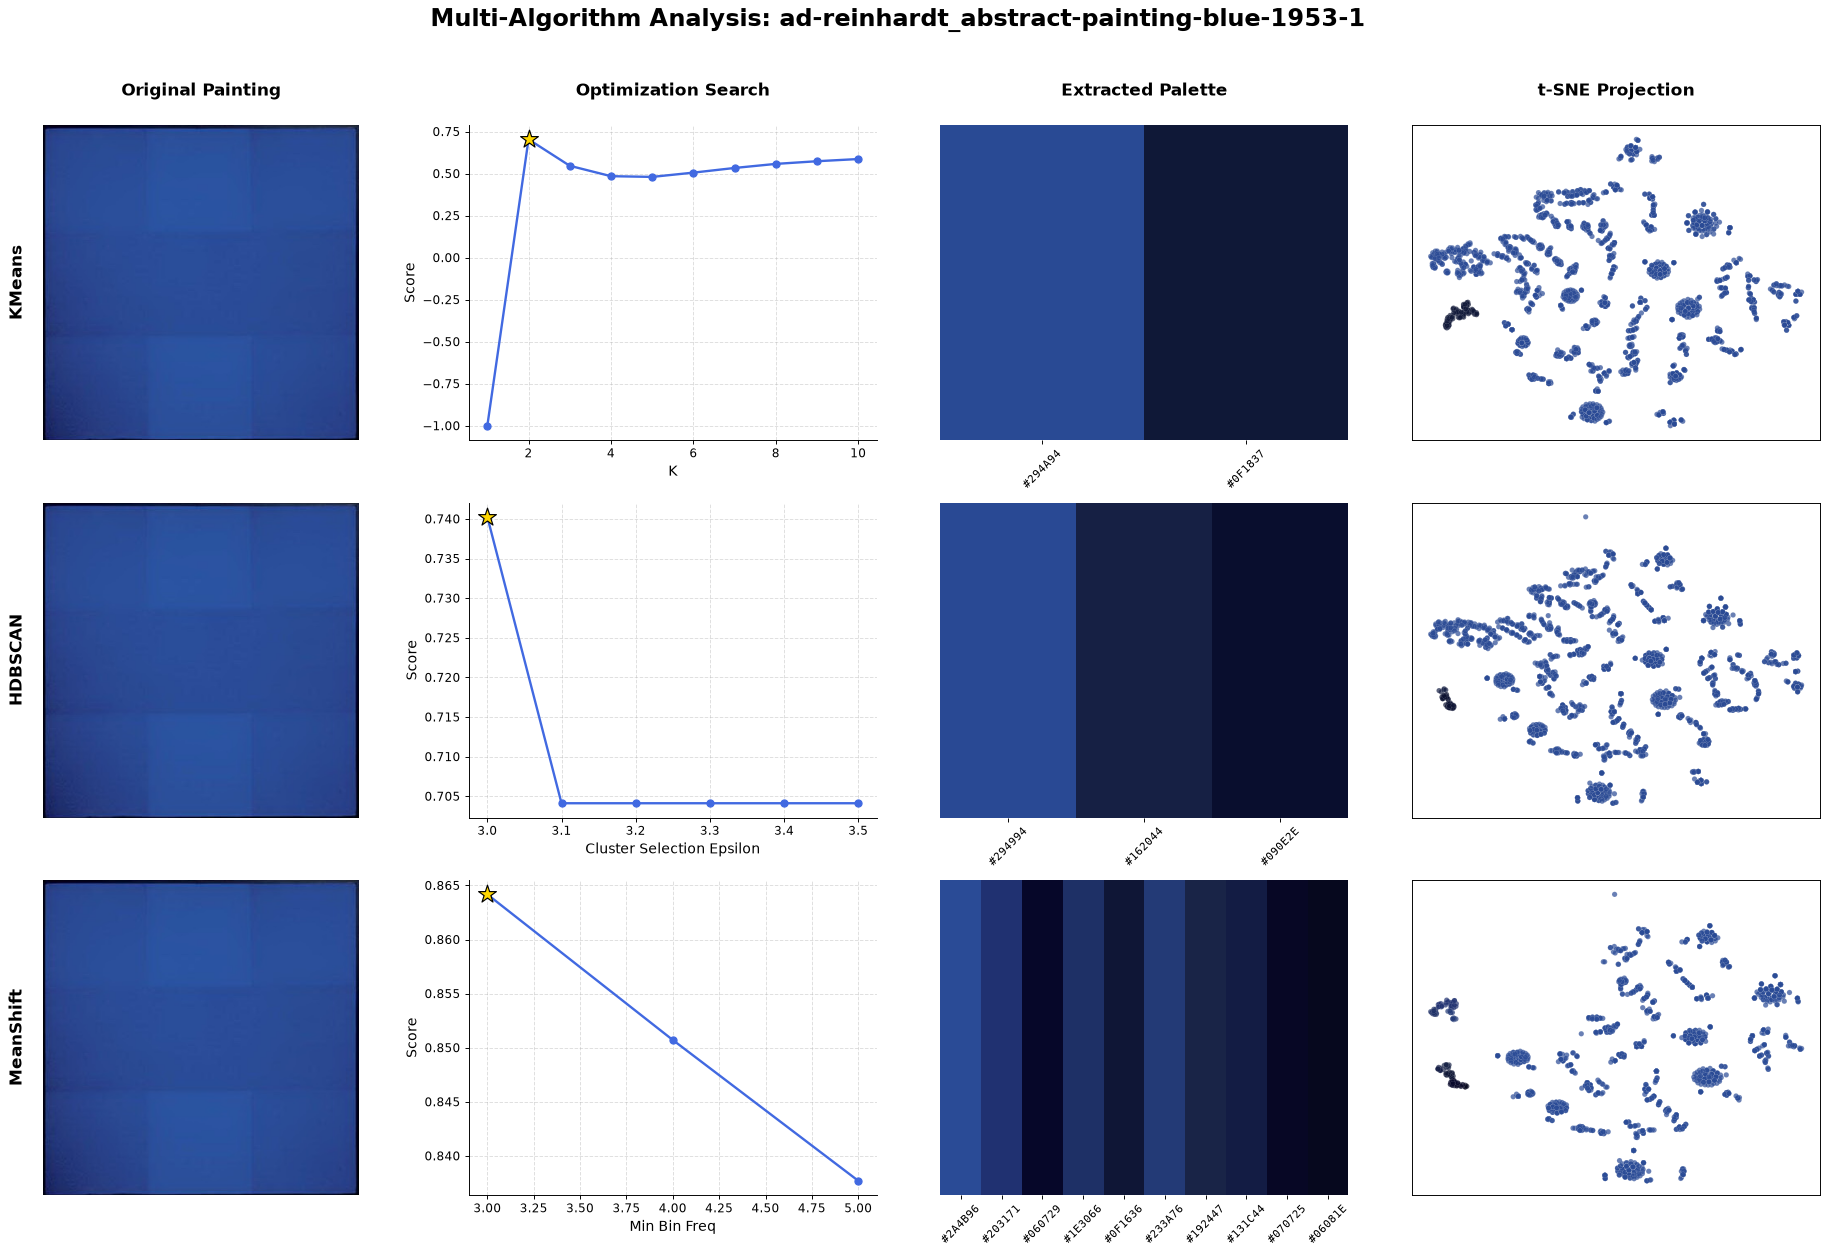

In [13]:
app.run_analysis("ad-reinhardt_abstract-painting-blue-1953-1.jpg")

### Análisis: Abstract Painting, Blue (1953)

* **KMeans**: Casi no logró encontrar diversidad en la pintura; el resultado es muy plano.
* **HDBSCAN**: Logró encontrar una diversidad moderada que respeta la composición.
* **MeanShift**: Logró encontrar una amplia diversidad de tonos, capturando detalles sutiles.

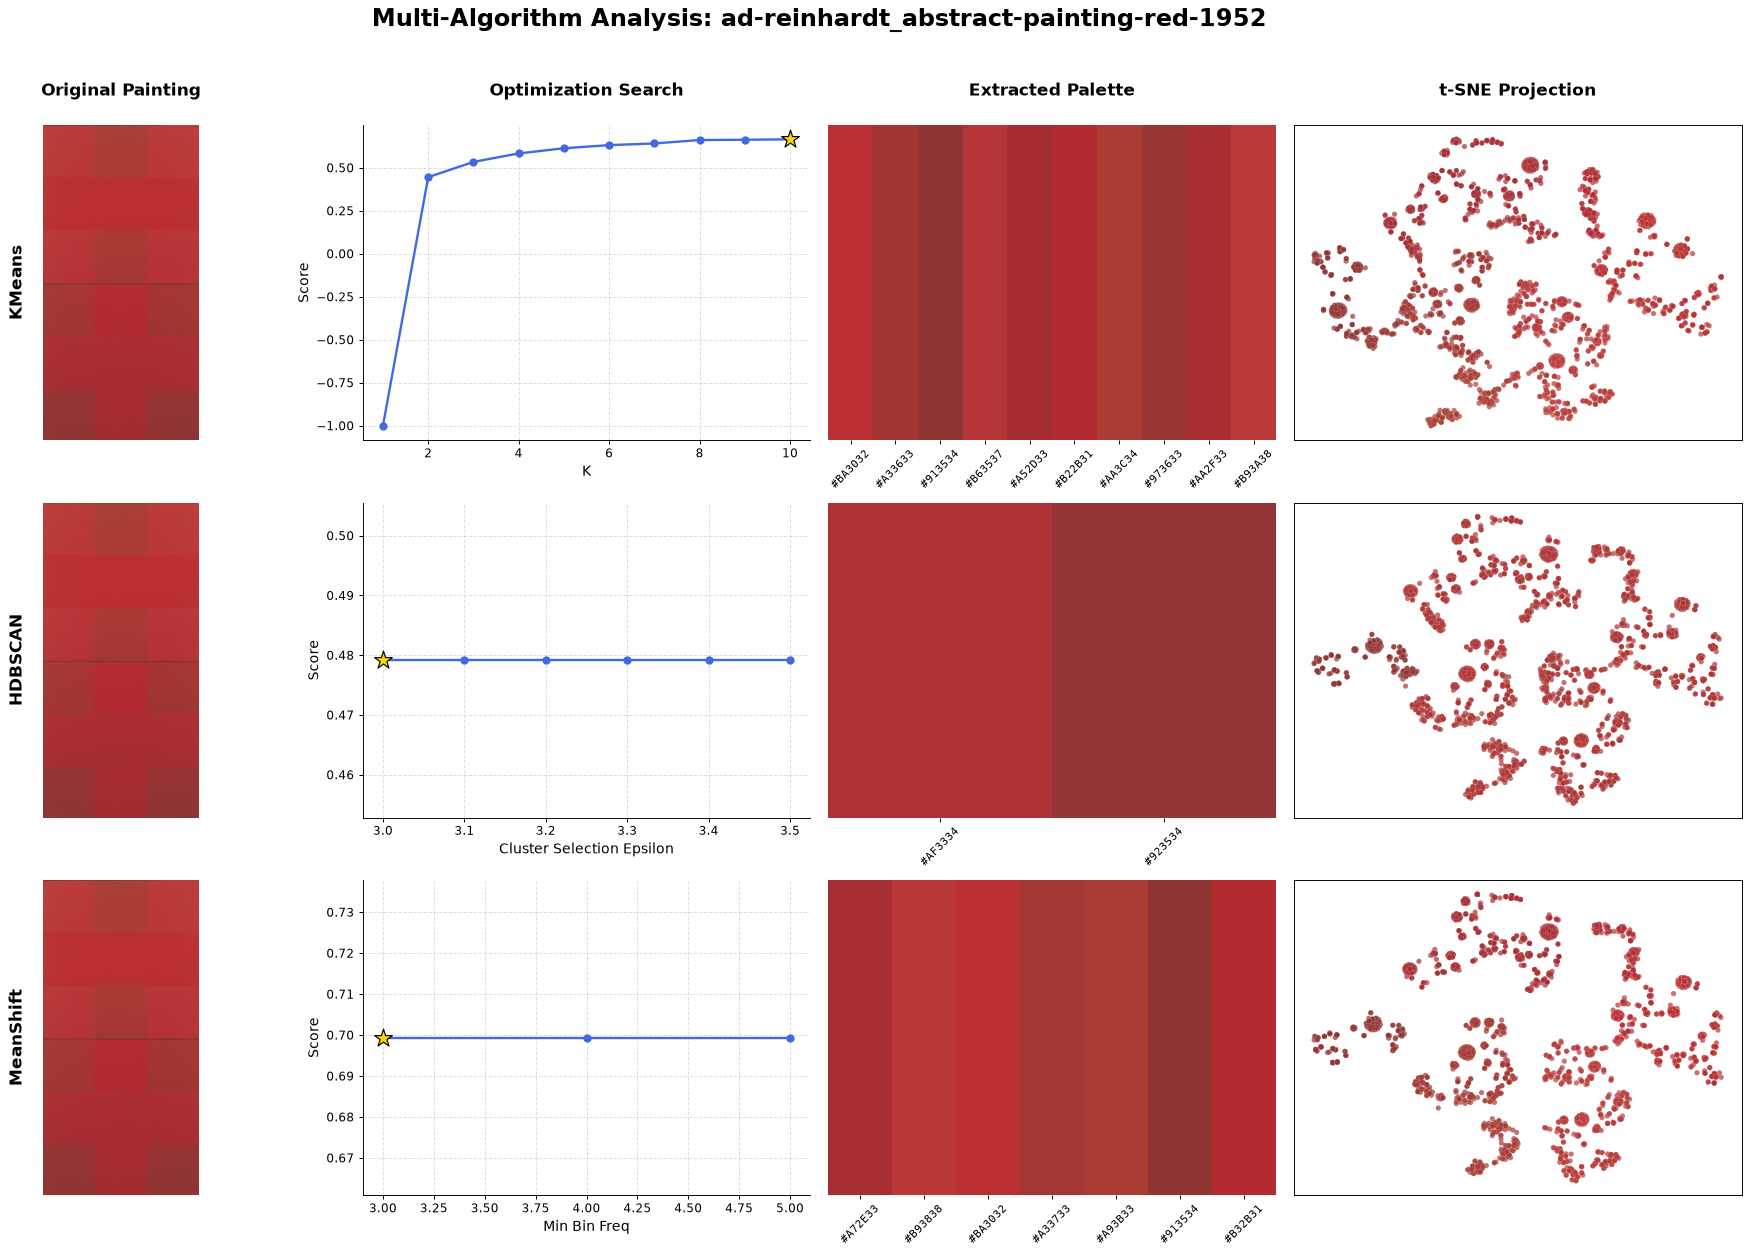

In [14]:
app.run_analysis("ad-reinhardt_abstract-painting-red-1952.jpg")

### Análisis: Abstract Painting, Red (1952)

* **KMeans**: Logró encontrar una amplia diversidad de tonos, capturando la mayoría de las variaciones presentes en la obra.
* **HDBSCAN**: Casi no logró encontrar diversidad; el resultado se reduce a solo dos bloques de color muy similares.
* **MeanShift**: Logró encontrar una amplia diversidad, identificando múltiples matices sutiles a lo largo de la composición.

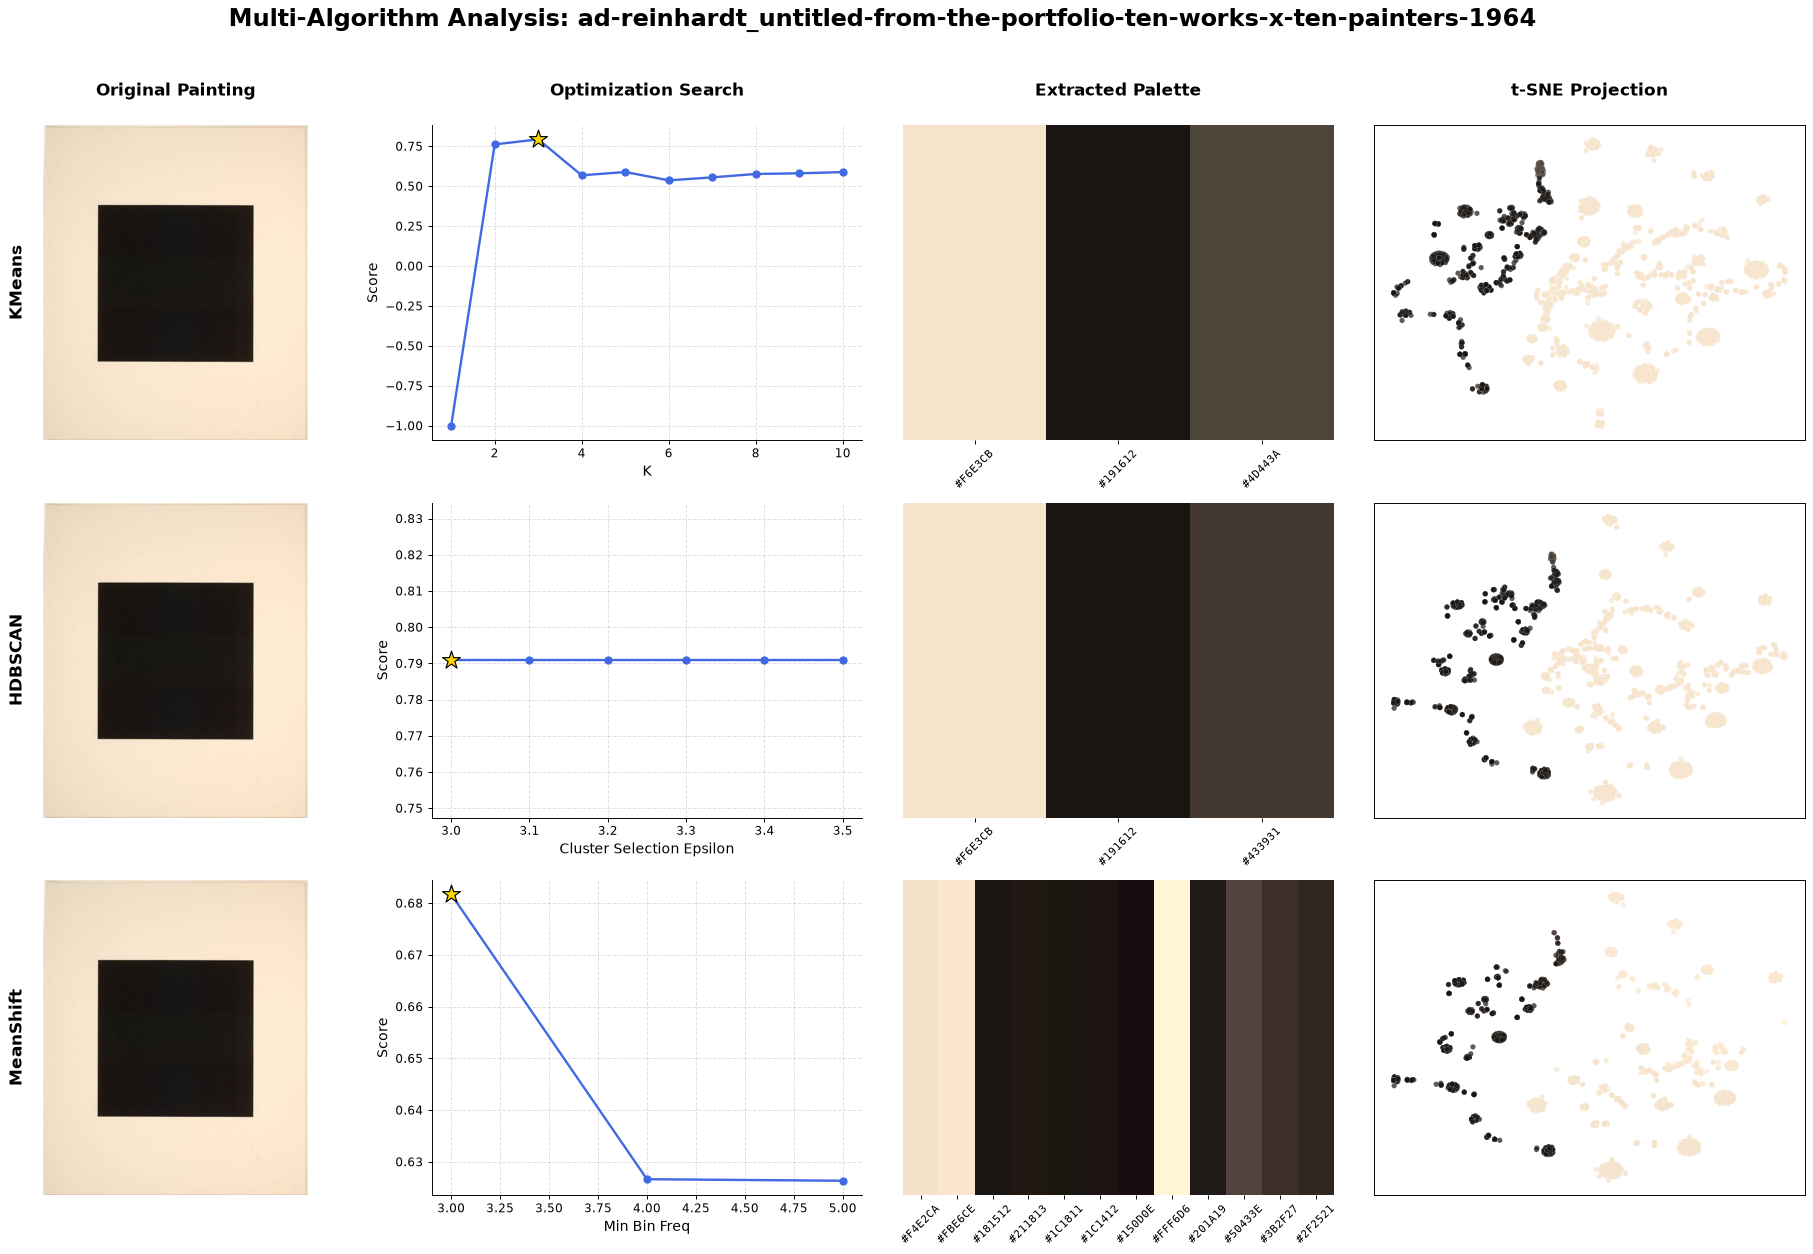

In [15]:
app.run_analysis(
    "ad-reinhardt_untitled-from-the-portfolio-ten-works-x-ten-painters-1964.jpg"
)

### Análisis: Untitled from Ten Works by Ten Painters (1964)

* **KMeans**: Logró encontrar una diversidad moderada, identificando los tonos principales y un matiz intermedio.
* **HDBSCAN**: Resume la obra con tres tonos; conviene comparar si conserva las variaciones que nos interesan.
* **MeanShift**: Logró encontrar una amplia diversidad, detectando múltiples variaciones sutiles dentro de la composición.

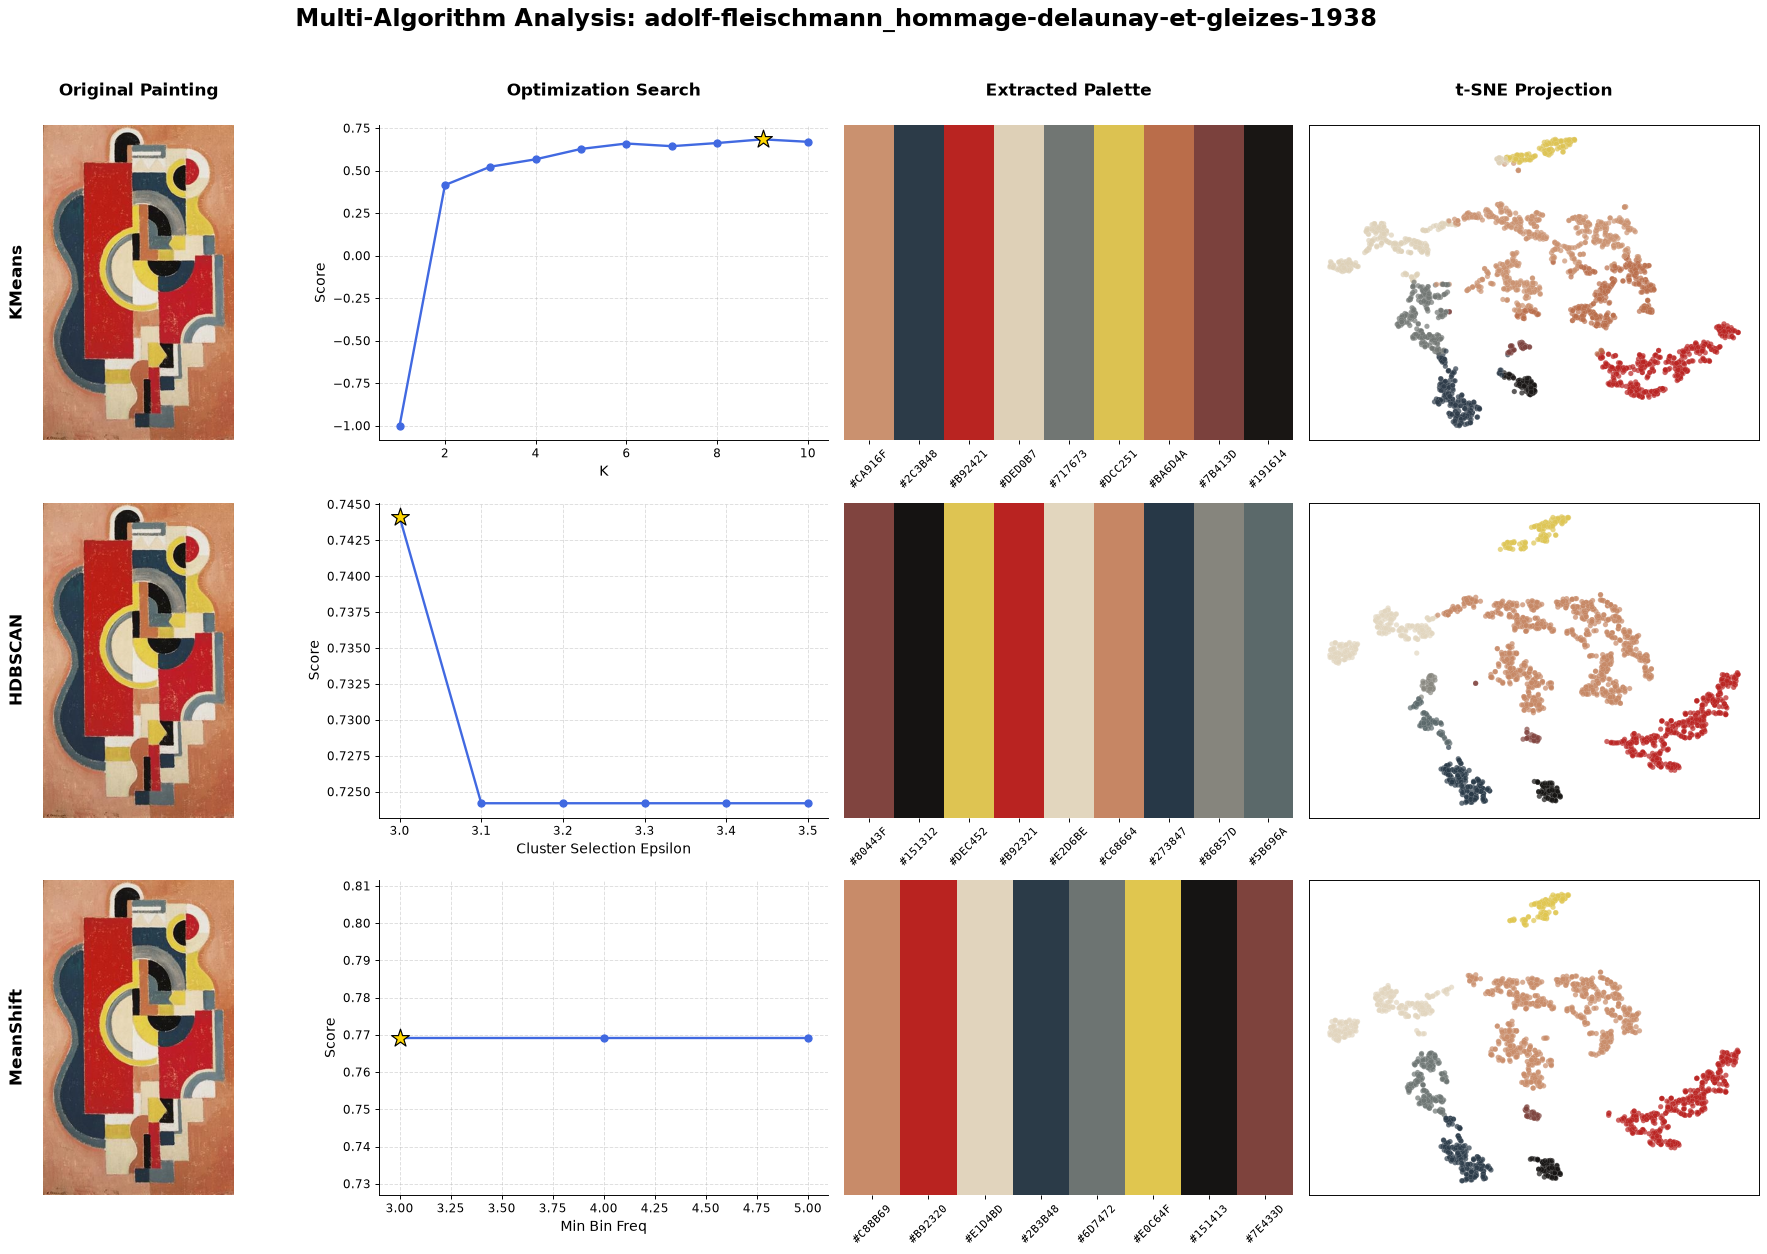

In [16]:
app.run_analysis("adolf-fleischmann_hommage-delaunay-et-gleizes-1938.jpg")

### Análisis: Hommage à Delaunay et Gleizes (1938)

* **KMeans**: Logró encontrar una amplia diversidad de colores, capturando los tonos primarios y neutros más importantes.
* **HDBSCAN**: Logró encontrar una amplia diversidad, identificando una gran variedad de matices distintos en la composición.
* **MeanShift**: Logró encontrar una amplia diversidad, detectando la mayoría de las variaciones cromáticas de la obra.

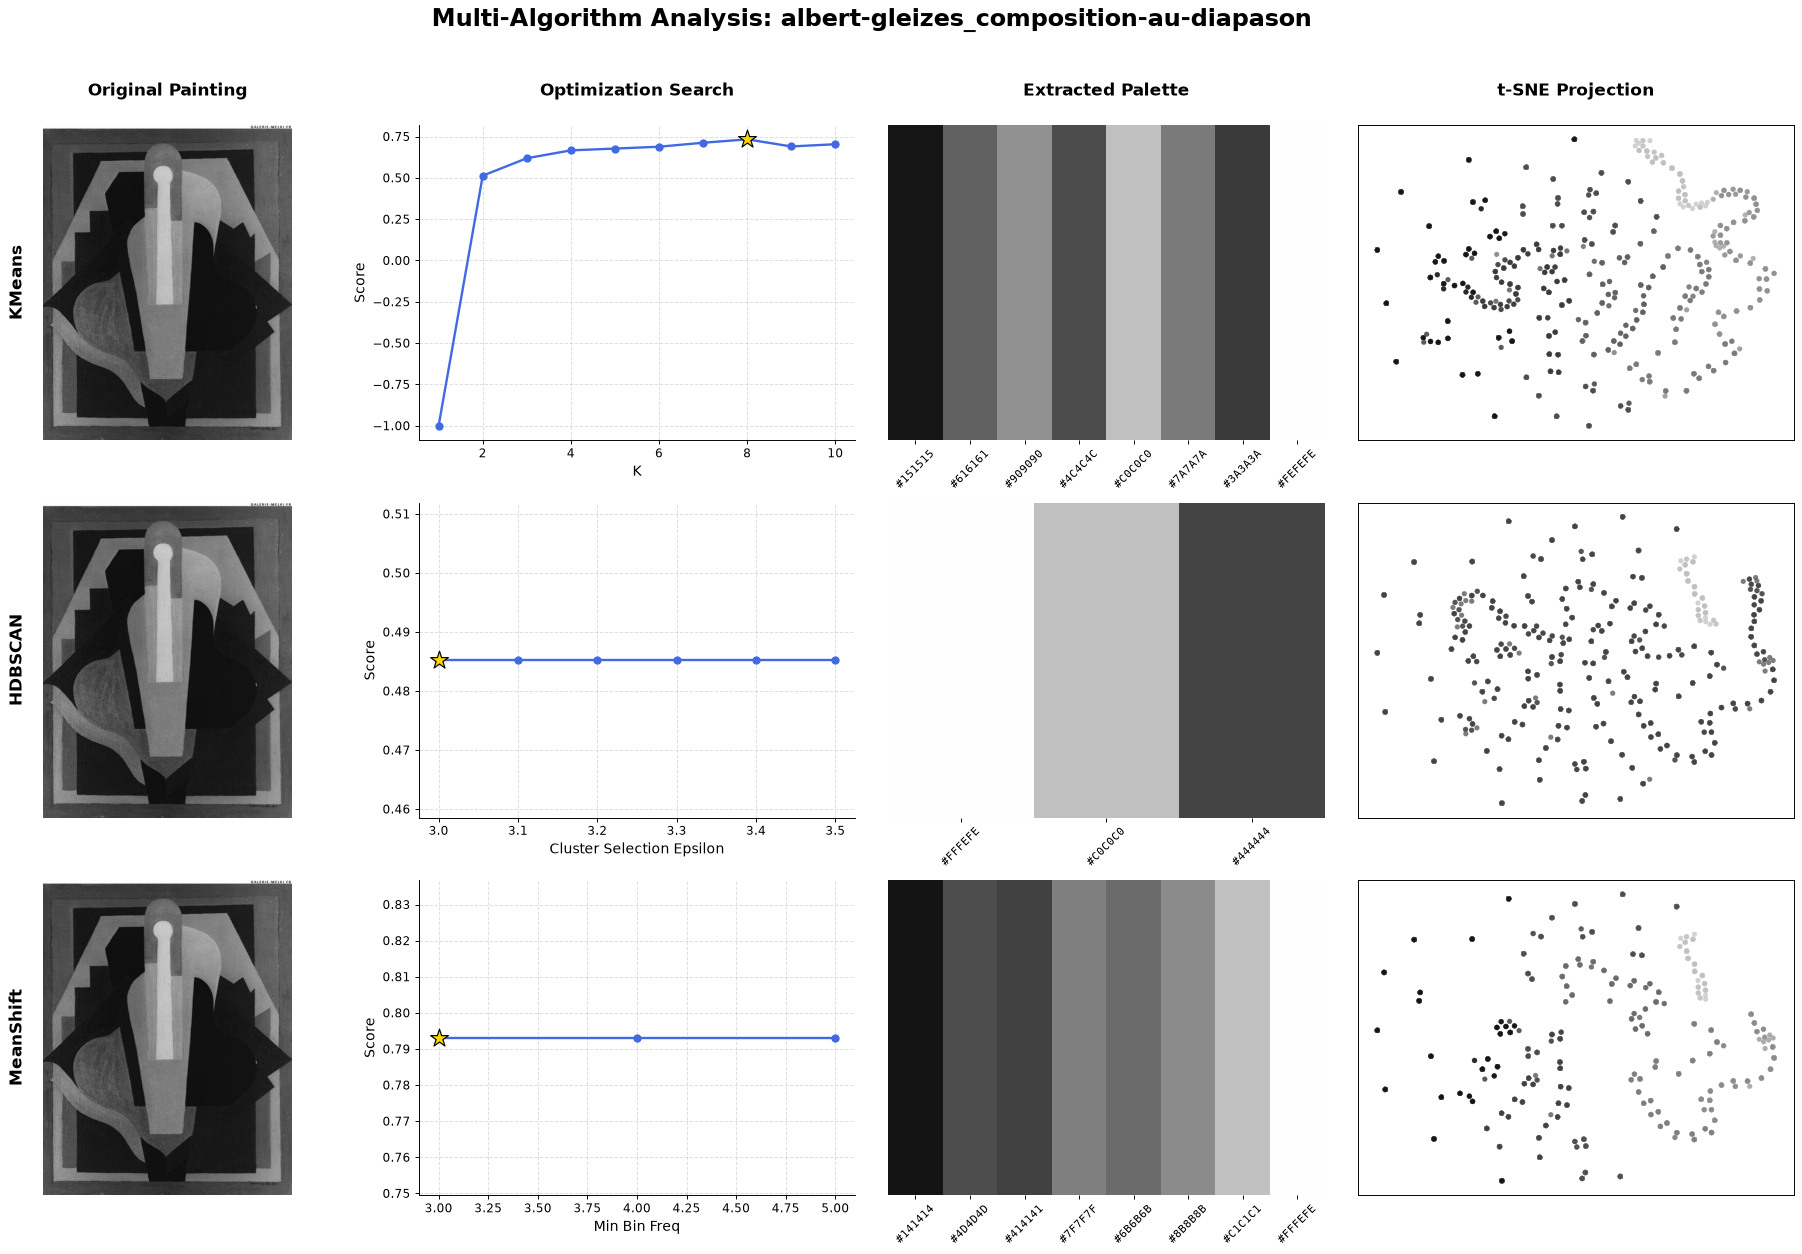

In [17]:
app.run_analysis("albert-gleizes_composition-au-diapason.jpg")

### Análisis: Composition au Diapason

* **KMeans**: Logró encontrar una amplia diversidad de tonos, identificando una gama variada de grises y neutros.
* **HDBSCAN**: Resume la obra con tres tonos de gris, por lo que ofrece menos detalle que las otras dos paletas en esta ejecución.
* **MeanShift**: Logró encontrar una amplia diversidad, detectando múltiples gradaciones sutiles dentro de la escala de grises.

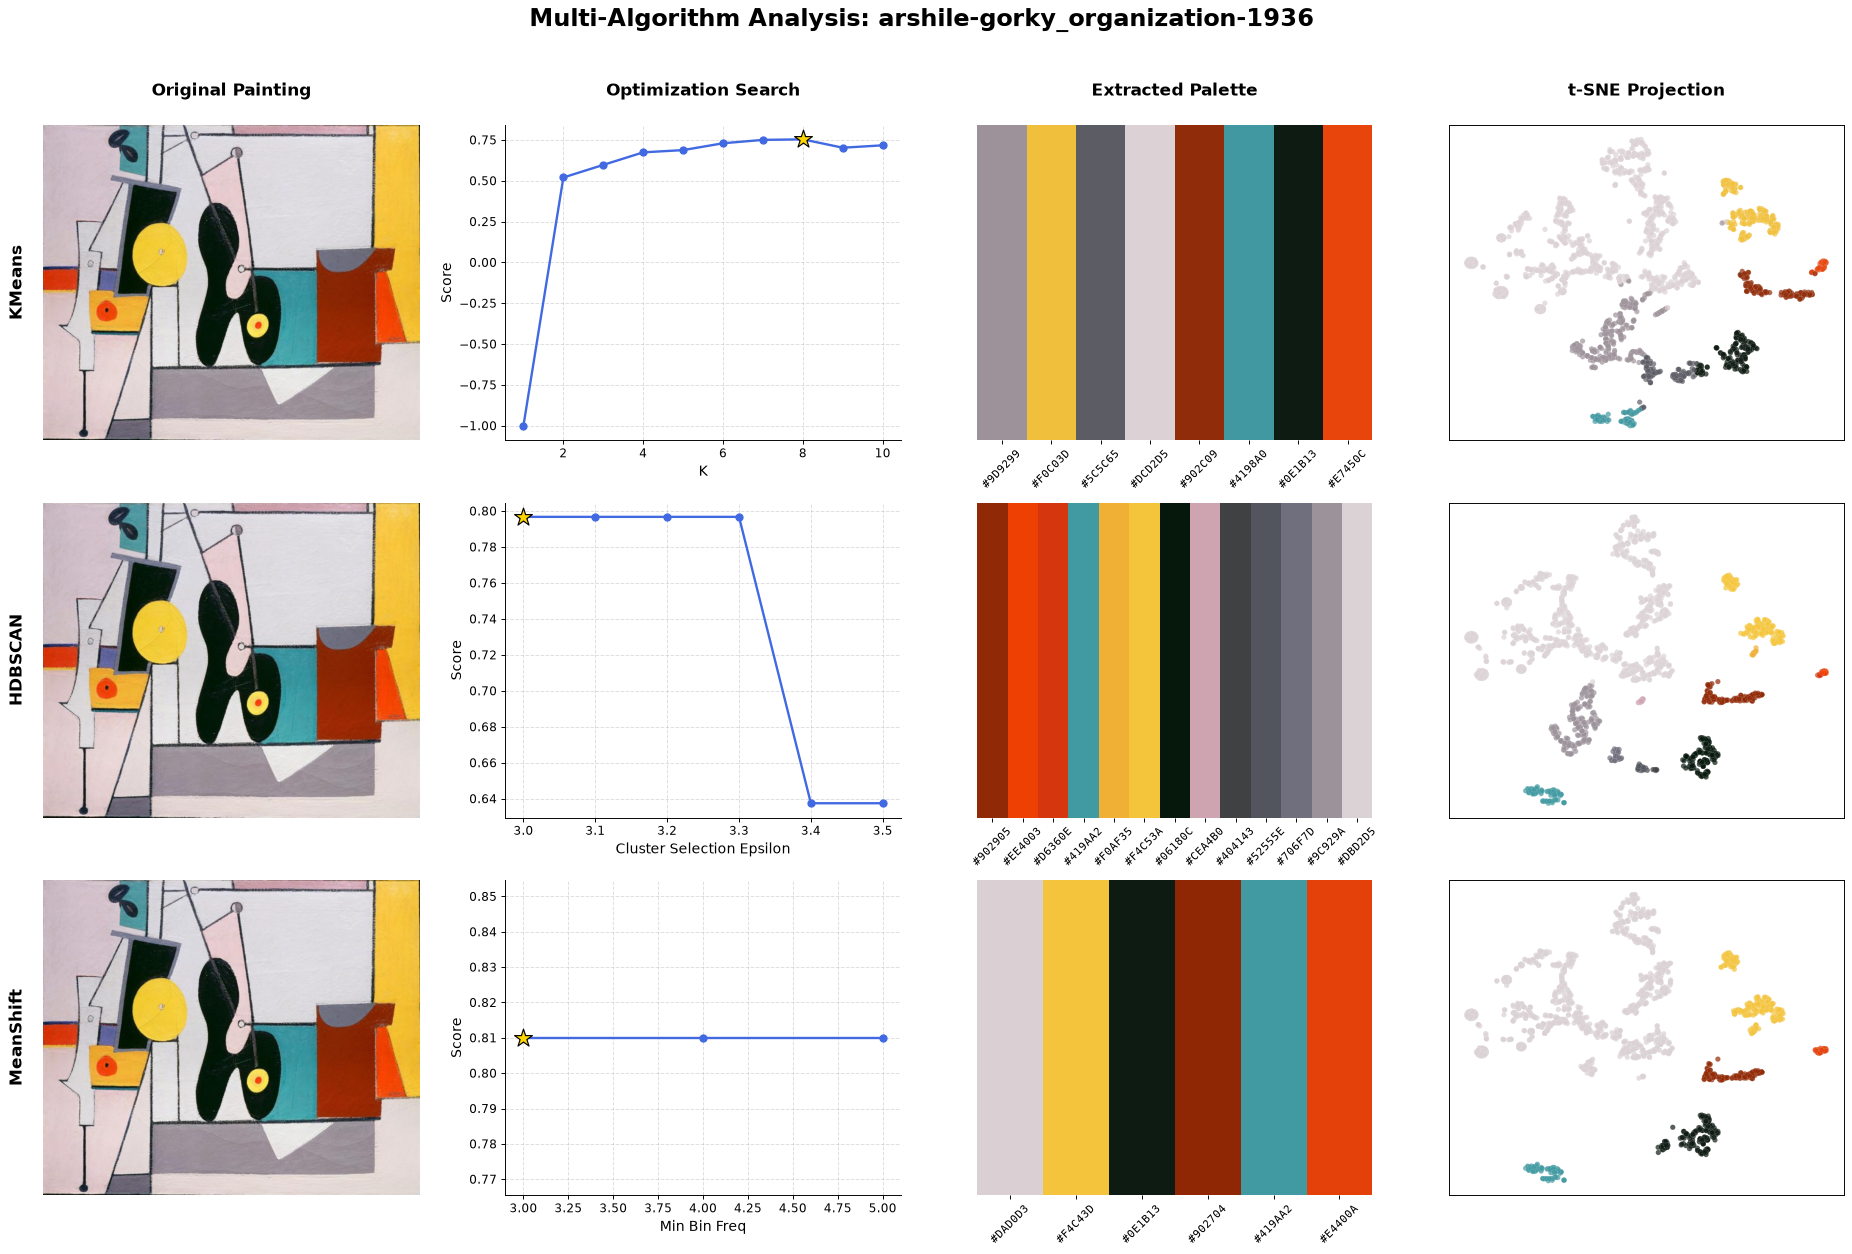

In [18]:
app.run_analysis("arshile-gorky_organization-1936.jpg")

### Análisis: Organization (1936)

* **KMeans**: Logró encontrar una amplia diversidad de colores, extrayendo una paleta variada que representa bien los elementos de la obra.
* **HDBSCAN**: Logró encontrar una amplia diversidad, identificando una gran cantidad de matices y tonos específicos por separado.
* **MeanShift**: Logró encontrar una amplia diversidad, detectando los colores principales y sus contrastes más marcados.

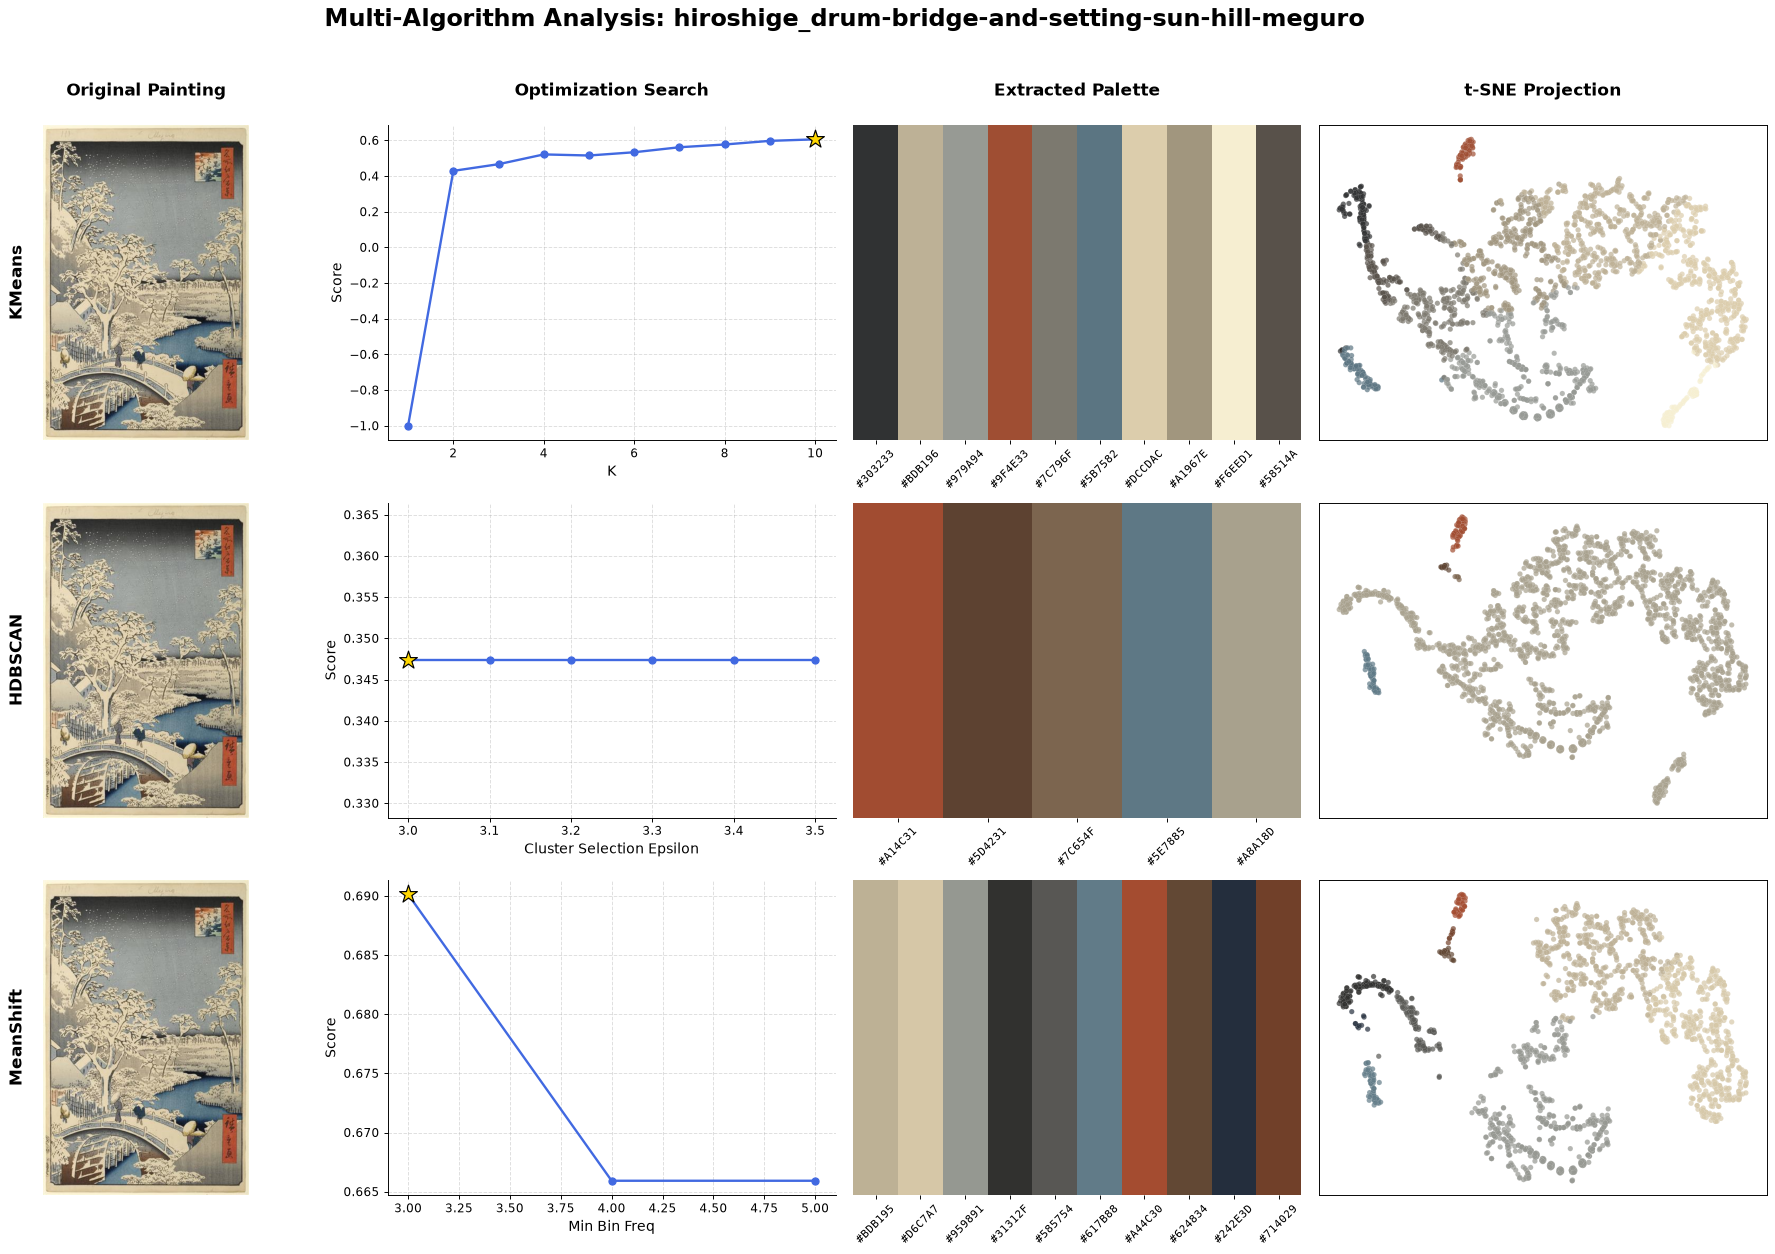

In [19]:
app.run_analysis("hiroshige_drum-bridge-and-setting-sun-hill-meguro.jpg")

### Análisis: Drum Bridge and Setting Sun, Hill Meguro

* **KMeans**: Logró encontrar una amplia diversidad de tonos, capturando bien la transición entre los azules del cielo y los neutros de la nieve.
* **HDBSCAN**: Logró encontrar una amplia diversidad, identificando matices específicos en las sombras y los detalles del puente.
* **MeanShift**: Logró encontrar una amplia diversidad, detectando la mayoría de las variaciones cromáticas, incluyendo los tonos amarillentos.

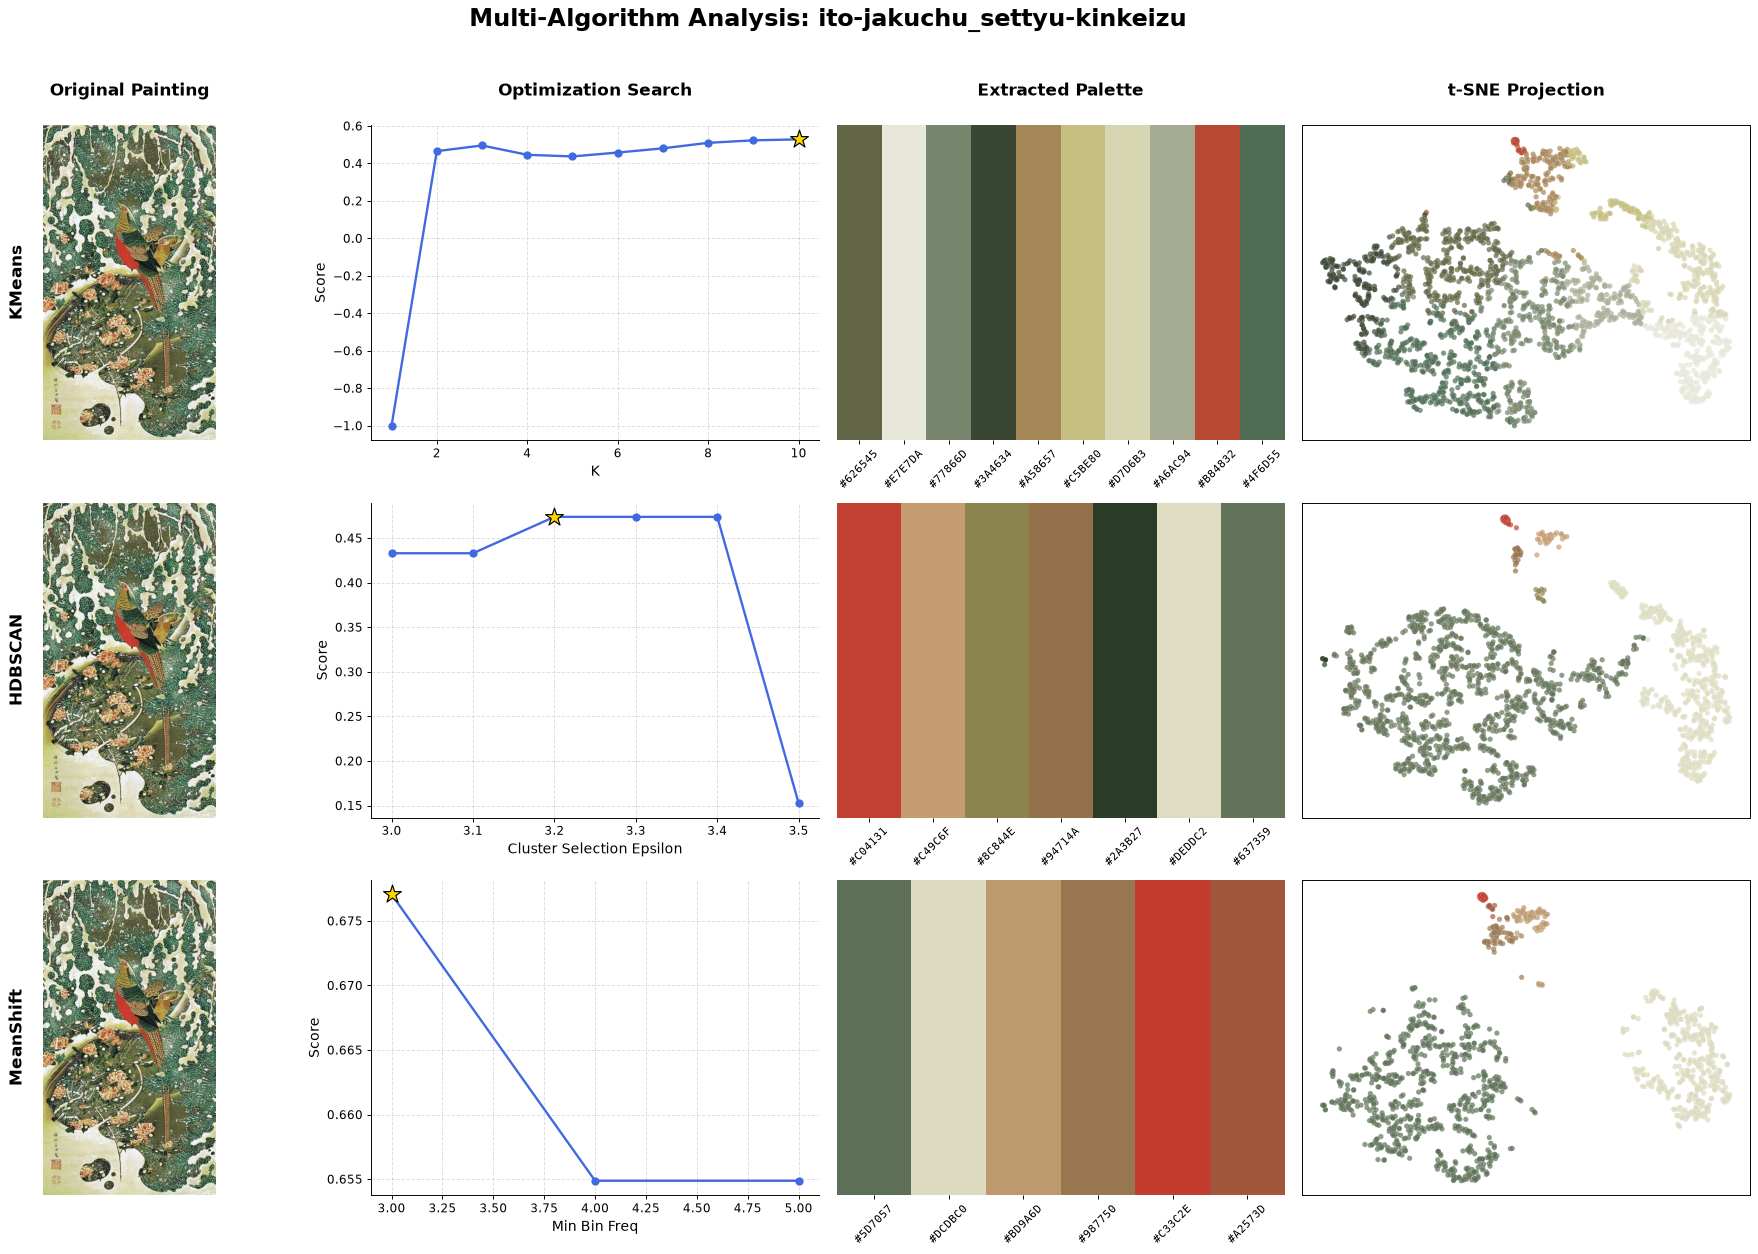

In [20]:
app.run_analysis("ito-jakuchu_settyu-kinkeizu.jpg")

### Análisis: Settyu Kinkeizu

* **KMeans**: Logró encontrar una amplia diversidad de tonos, identificando una gama extensa de verdes, tierras y neutros que componen la naturaleza de la obra.
* **HDBSCAN**: Logró encontrar una diversidad moderada, agrupando los elementos en los bloques de color más representativos del plumaje y el follaje.
* **MeanShift**: Logró encontrar una amplia diversidad, detectando múltiples variaciones sutiles y matices específicos en las texturas de la nieve y las plantas.

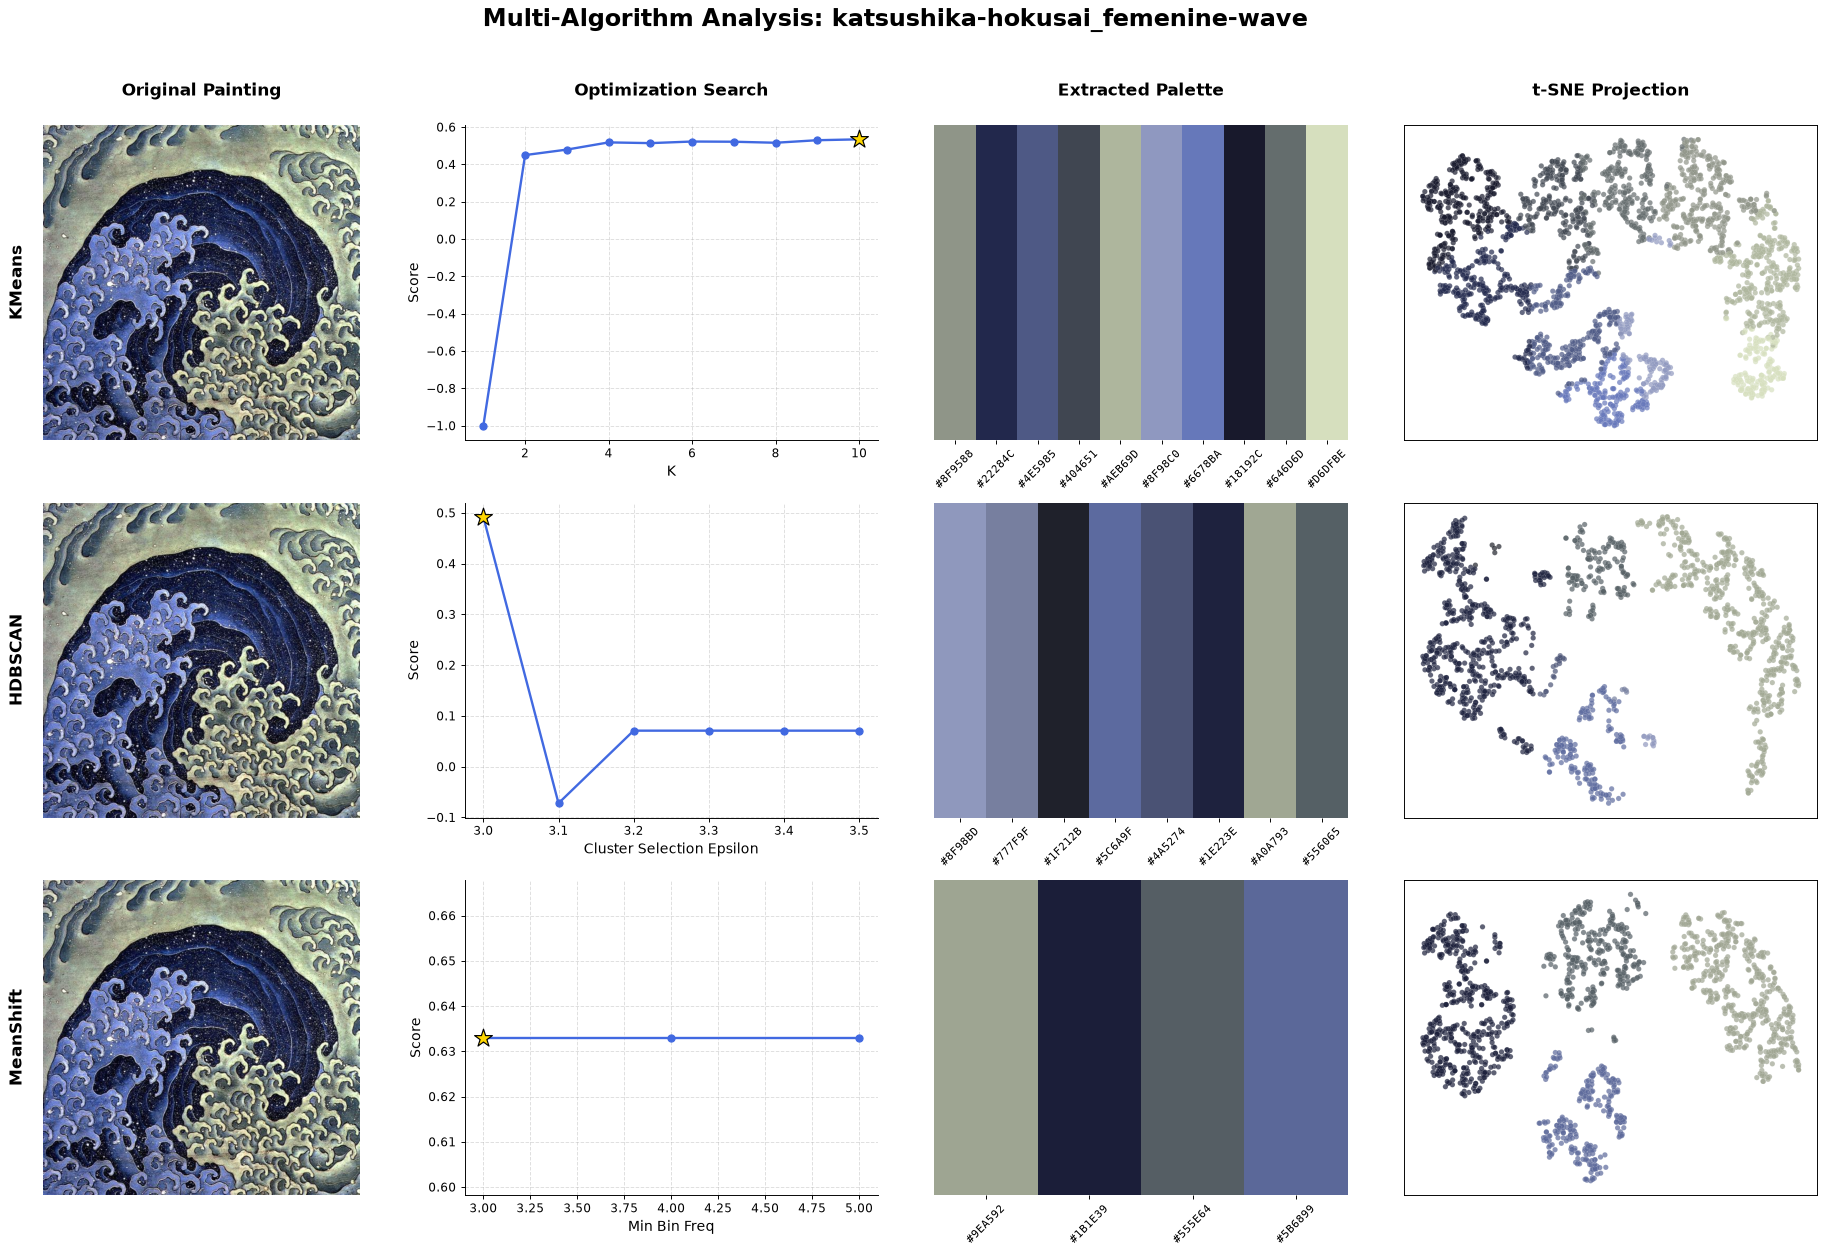

In [21]:
app.run_analysis("katsushika-hokusai_femenine-wave.jpg")

### Análisis: Feminine Wave

* **KMeans**: Logró encontrar una amplia diversidad de tonos, capturando la escala completa de azules, grises y los neutros de la espuma.
* **HDBSCAN**: Logró encontrar una amplia diversidad, identificando distintos matices de azul profundo y tonos grisáceos por separado.
* **MeanShift**: Logró encontrar una amplia diversidad, detectando variaciones sutiles en los degradados del agua y las zonas más claras de la cresta.

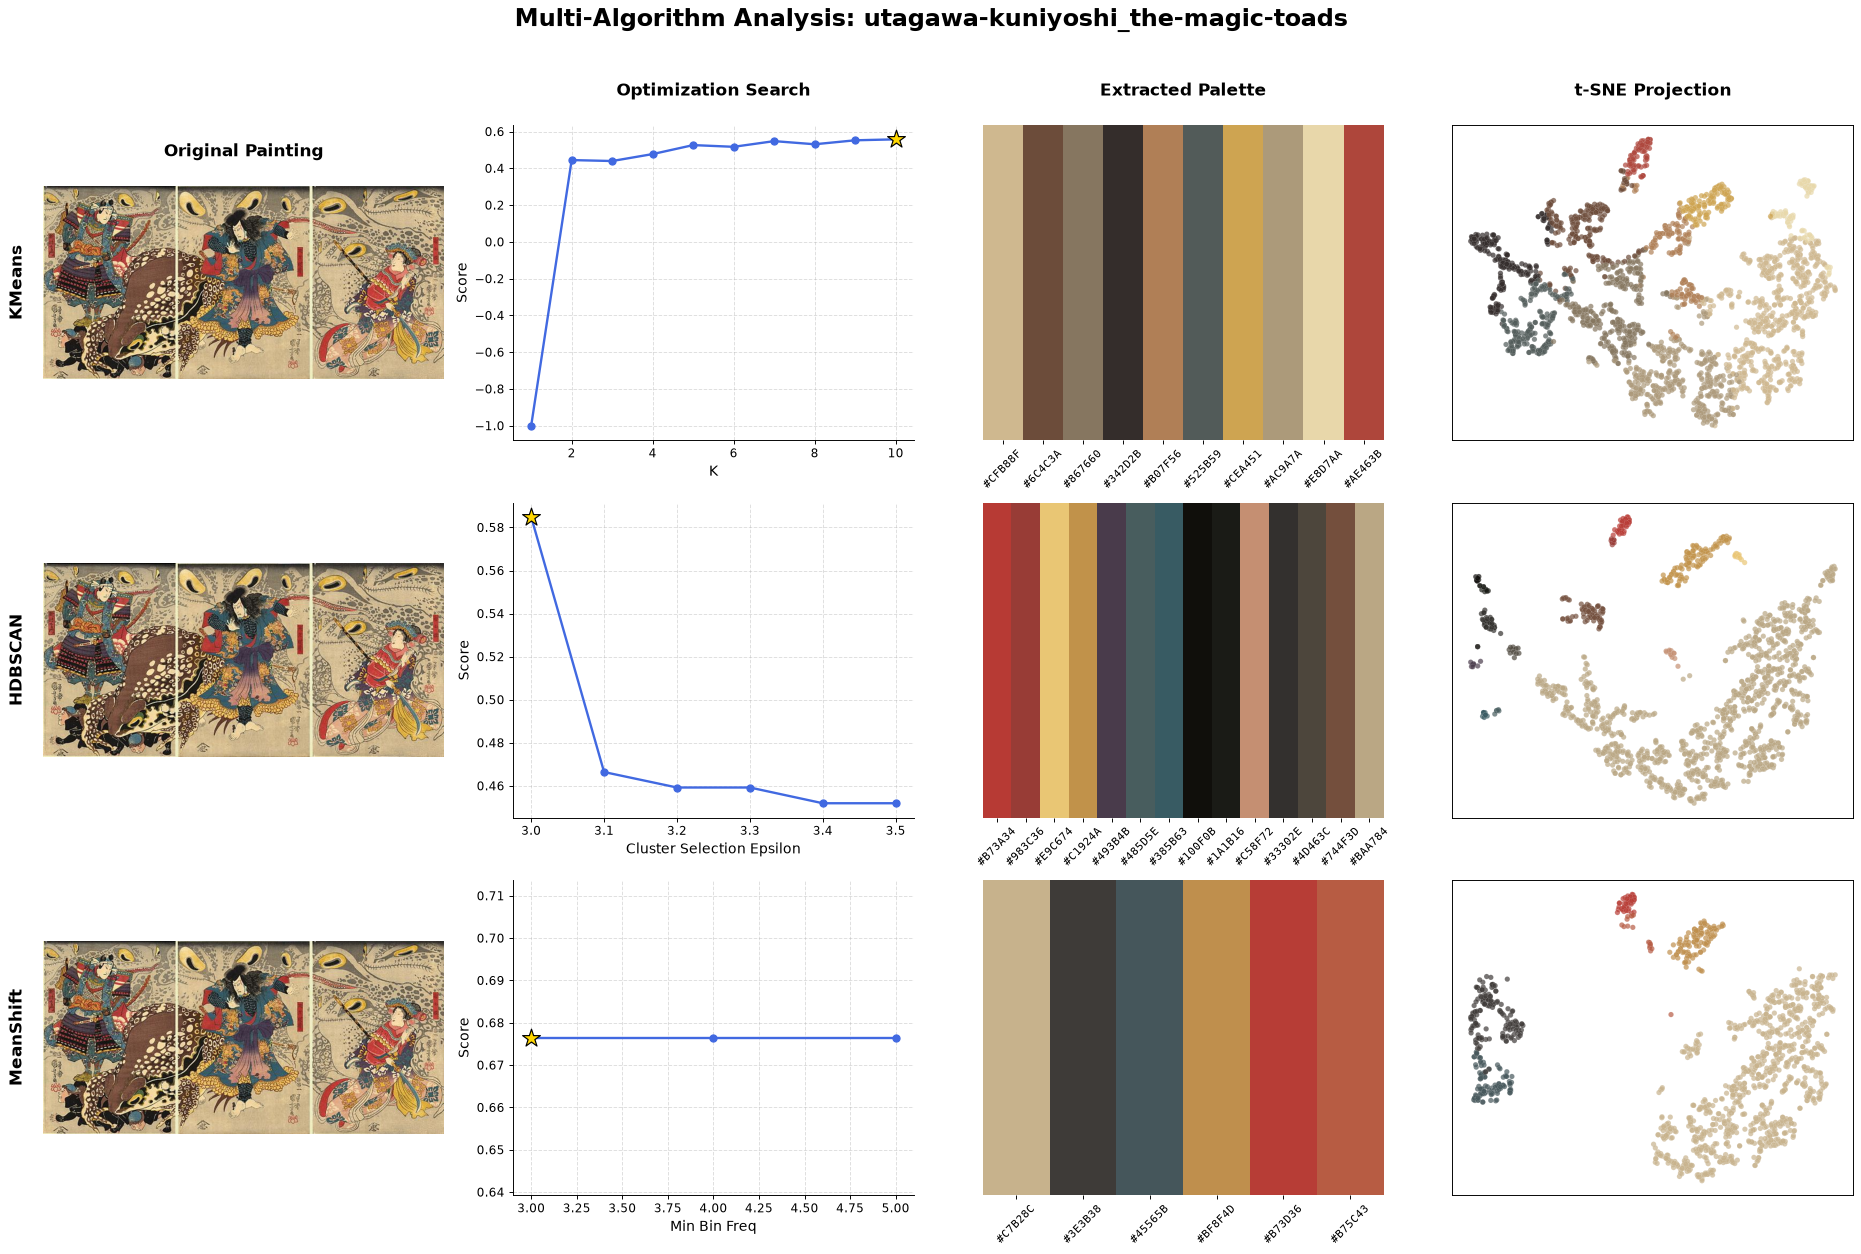

In [22]:
app.run_analysis("utagawa-kuniyoshi_the-magic-toads.jpg")

### Análisis: The Magic Toads

* **KMeans**: La paleta resume la imagen con diez colores, incluyendo tonos claros, oscuros y acentos de las figuras.
* **HDBSCAN**: La paleta incluye catorce colores y deja aproximadamente un 38 % de la muestra como ruido. La mayor cantidad de colores describe solo los píxeles asignados.
* **MeanShift**: La paleta incluye seis colores y deja aproximadamente un 46 % de la muestra sin grupo. Revisamos si los tonos conservados son suficientes para nuestro objetivo.


### ¿Cómo elegir una paleta para usarla?

| Necesidad | Punto de partida | Qué revisar |
| --- | --- | --- |
| Pedir una cantidad concreta de colores. | K-Means con un `k` elegido según el diseño. | Si los promedios ocultan acentos relevantes. |
| Explorar agrupamientos por densidad. | HDBSCAN. | Cuántos píxeles quedan como ruido y qué tonos representan. |
| Explorar concentraciones a una escala de color. | Mean Shift. | Sensibilidad al ancho de ventana y redundancia de tonos. |

El mejor punto de partida depende del uso. Una identidad visual puede necesitar
pocos colores bien diferenciados; un estudio de matices puede necesitar más.
Ninguna de estas preferencias se deduce automáticamente de una silueta alta.

## 7. Conclusiones

Aprendimos a trabajar sin una respuesta etiquetada: cada modelo propone grupos
a partir de similitudes entre píxeles. K-Means usa centros y una cantidad de
grupos definida; HDBSCAN busca estructura por densidad; Mean Shift se desplaza
hacia concentraciones de color.

La representación importa. CIELAB aproxima diferencias perceptuales y el
aplanado permite agrupar colores, pero pierde la posición. Reducir y muestrear
agiliza el cálculo a cambio de poder omitir detalles pequeños.

La silueta resume cohesión y separación. El puntaje del proyecto añade una
preferencia por más colores; sus pesos y su referencia de diez grupos son
decisiones que debemos justificar. Excluir ruido también cambia qué píxeles
estamos evaluando.

Estos resultados describen las imágenes, muestras y configuraciones usadas.
Para estudiar estabilidad podríamos repetir con otras semillas, registrar
silueta y ruido por separado y comparar muestras comunes. Conservamos los
centros LAB separados de la paleta RGB y reutilizamos las etiquetas del ajuste
para que el reporte mantenga la correspondencia entre puntos y colores.

## Referencias

Documentación oficial para consultar los conceptos y las herramientas de la sesión.

### Preparación de imágenes

- [Pillow: Image](https://pillow.readthedocs.io/en/stable/reference/Image.html): apertura, conversión y cambio de tamaño.
- [scikit-image: espacios y conversiones de color](https://scikit-image.org/docs/stable/api/skimage.color.html): `rgb2lab`, `lab2rgb` y diferencias de color.

### Modelos

- [scikit-learn: agrupamiento](https://scikit-learn.org/stable/modules/clustering.html): familias de modelos y criterios de evaluación.
- [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).
- [HDBSCAN: selección de parámetros](https://hdbscan.readthedocs.io/en/latest/parameter_selection.html) y [API del paquete hdbscan](https://hdbscan.readthedocs.io/en/latest/api.html).
- [MeanShift](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MeanShift.html) y [estimate_bandwidth](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.estimate_bandwidth.html).

### Evaluación y visualización

- [Silhouette Score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [TSNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html).
- [resample](https://scikit-learn.org/stable/modules/generated/sklearn.utils.resample.html): selección de muestras y reemplazo.

### Introducción: anomalías, etiquetas y representaciones

- [Detección de outliers y novedades](https://scikit-learn.org/stable/modules/outlier_detection.html), [IsolationForest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html) y [LOF](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html).
- [Aprendizaje semi supervisado](https://scikit-learn.org/stable/modules/semi_supervised.html), [LabelSpreading](https://scikit-learn.org/stable/modules/generated/sklearn.semi_supervised.LabelSpreading.html) y [SelfTrainingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.semi_supervised.SelfTrainingClassifier.html).
- [Devlin y colaboradores: BERT](https://arxiv.org/abs/1810.04805).
- [Chen y colaboradores: SimCLR](https://arxiv.org/abs/2002.05709).
- [Sohn y colaboradores: FixMatch](https://arxiv.org/abs/2001.07685).
- [Caron y colaboradores: DeepCluster](https://arxiv.org/abs/1807.05520).


### Reglas de asociación

- [mlxtend: reglas y métricas de asociación](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/).
- [Apriori](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/) y [FP-Growth](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/fpgrowth/): búsqueda de conjuntos frecuentes.

### Pinturas

- [WikiArt](https://www.wikiart.org/): fuente de las reproducciones utilizadas en el laboratorio.
